# Information Theory from Scratch

**Companion notebook 00 for W41-W42 — The Information Domain.**
Pairs with [Information Theory Explained](https://artifocial.com/blog/information-theory-explained-2026-oct-15)
and the flagship [The Information Domain](https://artifocial.com/blog/information-domain-2026-oct-8).

Everything here is **pure NumPy**. No PyTorch, no JAX, no `scipy.stats`. Gradients are derived by
hand and checked against finite differences. Every claim in the companion articles that carries a
number is a number printed by this notebook.

### What this notebook establishes

1. **Entropy, cross-entropy, KL and mutual information** implemented from their definitions, with
   the identities between them verified numerically rather than asserted.
2. **Why your loss never reaches zero with label smoothing** — the floor is an entropy, and we
   compute it exactly.
3. **The plug-in mutual-information estimator is biased, and the sign of the bias depends on the
   regime.** Under independence on the sample sizes practitioners use it reads high, badly, and we
   measure that against the analytic prediction. On a strongly dependent pair observed on a sparse
   table it reads *low*, and we measure that too. A permutation null at your own $N$ and bins is the
   error bar you can actually earn.
4. **The information plane**, reproduced for `tanh` and `ReLU` networks — and the measurement that
   started a decade-long argument, including the part where *the conclusion changes when you change
   the bin count* and the part where the **exact** quantity for this finite-support experiment is
   computed with no estimator at all — at every checkpoint, so you can see *when* inputs started
   colliding, and for a noisy representation, where the mutual information is an exact Monte Carlo
   expectation over a known mixture rather than an estimate.
5. **Rate–distortion**, via the Blahut–Arimoto algorithm, checked against the two cases with
   closed-form answers.
6. **The kernel ↔ Fourier ↔ entropy-rate triangle**: the differential entropy rate of a stationary
   Gaussian process computed two completely different ways — a log-determinant in the space domain,
   and the **log-average** of the spectral density in the frequency domain
   ([W38](https://artifocial.com/blog/frequency-domain-2026-sep-17)) — agreeing to within $10^{-8}$
   across every case tested. That is the circulant form of the Kolmogorov–Szegő identity; the Toeplitz
   *limit* the theorem is about is tested separately on an AR(1), and the wrapped-RBF rows are shown to be
   dominated by the diagonal jitter rather than by the process. It is *not* the Shannon entropy of the
   normalised spectrum, and one cell shows the two functionals coming apart.

### What this notebook does *not* do

It does not estimate mutual information in high dimensions, because on the sample sizes available to
a notebook that cannot be done honestly. Section 4 is the reason, and it is the most practically
useful section here.

In [1]:
import sys, platform
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

matplotlib.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110, "font.size": 10,
    "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False,
    "axes.spines.right": False, "figure.autolayout": True,
})

SEED = 20260921
rng = np.random.default_rng(SEED)

print("Python     ", sys.version.split()[0], "on", platform.system())
print("NumPy      ", np.__version__)
print("Matplotlib ", matplotlib.__version__)
print("Seed       ", SEED)
print("Machine    ", platform.machine(), "|", platform.platform())
try:
    _blas = np.show_config(mode="dicts").get("Build Dependencies", {}).get("blas", {})
    print("BLAS       ", _blas.get("name", "?"), "(NumPy's build-time BLAS: the backend every matmul below runs on)")
except Exception as _e:
    print("BLAS       ", "unavailable:", _e)
print("Float dtype", np.asarray(1.0).dtype, "(NumPy's default; every array in this notebook is float64 unless it is cast)")
print()
print("Reproducibility scope: with this Python, NumPy, OS and BLAS, a re-execution reproduces every printed number")
print("except wall-clock timings. On another platform the two 4,000-epoch trainings in Section 5 can land on")
print("different weights from the same seed, and the exact collision counts there are sensitive to that;")
print("the published reference weights (nb00_trained_params.npz) let that representation be evaluated without retraining; a re-execution saves its own weights as nb00_trained_params.local.npz and reports whether they match.")

Python      3.14.5 on Darwin
NumPy       2.5.3
Matplotlib  3.11.1
Seed        20260921
Machine     x86_64 | macOS-26.4.1-x86_64-i386-64bit-Mach-O
BLAS        accelerate (NumPy's build-time BLAS: the backend every matmul below runs on)
Float dtype float64 (NumPy's default; every array in this notebook is float64 unless it is cast)

Reproducibility scope: with this Python, NumPy, OS and BLAS, a re-execution reproduces every printed number
except wall-clock timings. On another platform the two 4,000-epoch trainings in Section 5 can land on
different weights from the same seed, and the exact collision counts there are sensitive to that;
the published reference weights (nb00_trained_params.npz) let that representation be evaluated without retraining; a re-execution saves its own weights as nb00_trained_params.local.npz and reports whether they match.


---
## 1. Entropy: the expected surprise

Shannon's entropy of a discrete distribution $p$ is

$$H(p) \;=\; -\sum_x p(x)\log p(x) \;=\; \mathbb{E}_{x\sim p}\!\left[\log \frac{1}{p(x)}\right].$$

The bracketed quantity $\log \tfrac{1}{p(x)}$ is the **surprisal** of outcome $x$: how startled you
should be to see it. Entropy is its average. Using $\log_2$ gives bits; using $\ln$ gives nats. We
default to bits because bits are the unit people have intuition for, and we will be explicit every
time it matters.

The only implementation subtlety is $p(x)=0$, where $p\log p$ is $0\cdot(-\infty)$. The limit is 0,
so we mask rather than clip. Clipping to a small $\varepsilon$ is the more common workaround and it
silently changes the answer; the mask does not.

In [2]:
def xlogx(p):
    """p * log2(p), with the correct limit 0 at p = 0 (masked, not clipped)."""
    p = np.asarray(p, dtype=float)
    out = np.zeros_like(p)
    nz = p > 0
    out[nz] = p[nz] * np.log2(p[nz])
    return out

def entropy(p, axis=-1):
    """Shannon entropy in bits."""
    return -np.sum(xlogx(p), axis=axis)

# Sanity checks against cases where the answer is known exactly.
k = 8
uniform = np.full(k, 1.0 / k)
point   = np.zeros(k); point[3] = 1.0
skewed  = np.array([0.5, 0.25, 0.125, 0.0625, 0.0625, 0.0, 0.0, 0.0])

print(f"H(uniform over {k})   = {entropy(uniform) + 0.0:.6f} bits   (exact: log2(8) = 3)")
print(f"H(point mass)        = {entropy(point) + 0.0:.6f} bits   (exact: 0)")
print(f"H(dyadic skewed)     = {entropy(skewed):.6f} bits   (exact: 1.875)")
print()
print("Maximum-entropy check over 200,000 random distributions on 8 outcomes:")
R = rng.dirichlet(np.ones(k), size=200_000)
H = entropy(R)
print(f"  max H found = {H.max():.6f} bits   vs uniform's {entropy(uniform):.6f}")
print(f"  exceeded uniform in {int((H > entropy(uniform) + 1e-12).sum())} of {len(H)} draws")

H(uniform over 8)   = 3.000000 bits   (exact: log2(8) = 3)
H(point mass)        = 0.000000 bits   (exact: 0)
H(dyadic skewed)     = 1.875000 bits   (exact: 1.875)

Maximum-entropy check over 200,000 random distributions on 8 outcomes:
  max H found = 2.979046 bits   vs uniform's 3.000000
  exceeded uniform in 0 of 200000 draws


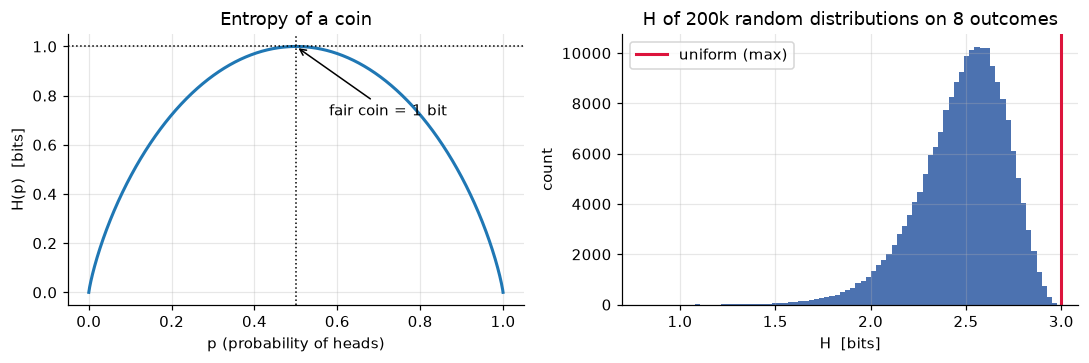

A fair coin is exactly 1 bit. A coin with p=0.9 is 0.4690 bits —
so nine-to-one odds have already destroyed more than half the uncertainty of a fair coin.


In [3]:
# The Bernoulli entropy curve: the whole of Section 1 in one picture.
p = np.linspace(0, 1, 1001)
Hb = -xlogx(p) - xlogx(1 - p)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].plot(p, Hb, lw=2)
ax[0].set_xlabel("p (probability of heads)"); ax[0].set_ylabel("H(p)  [bits]")
ax[0].set_title("Entropy of a coin")
ax[0].axvline(0.5, ls=":", c="k", lw=1); ax[0].axhline(1.0, ls=":", c="k", lw=1)
ax[0].annotate("fair coin = 1 bit", xy=(0.5, 1.0), xytext=(0.58, 0.72),
               arrowprops=dict(arrowstyle="->", lw=1))

ax[1].hist(H, bins=80, color="#4C72B0")
ax[1].axvline(entropy(uniform), c="crimson", lw=2, label="uniform (max)")
ax[1].set_xlabel("H  [bits]"); ax[1].set_ylabel("count")
ax[1].set_title("H of 200k random distributions on 8 outcomes")
ax[1].legend()
plt.show()

print(f"A fair coin is exactly 1 bit. A coin with p=0.9 is {(-xlogx(0.9)-xlogx(0.1)):.4f} bits —")
print("so nine-to-one odds have already destroyed more than half the uncertainty of a fair coin.")

---
## 2. Cross-entropy, KL divergence, and the identity that connects them

Cross-entropy is the average surprisal you suffer when you believe $q$ and reality is $p$:

$$H(p,q) \;=\; -\sum_x p(x)\log q(x).$$

KL divergence is the *excess* over the best you could have done:

$$D_{\mathrm{KL}}(p\,\|\,q) \;=\; \sum_x p(x)\log\frac{p(x)}{q(x)} \;=\; H(p,q) - H(p).$$

That rearrangement is the single most consequential identity in applied machine learning:

$$\boxed{\;H(p,q) \;=\; \underbrace{H(p)}_{\text{fixed by the data}} \;+\; \underbrace{D_{\mathrm{KL}}(p\|q)}_{\text{all you can optimise}}\;}$$

For fixed targets, minimising cross-entropy **is** minimising a forward KL divergence. The two differ
by a constant your model cannot touch. That is a distribution-fitting identity — KL projection of the
data onto the model class — and it is why the same machinery reappears in VAEs, diffusion models and
the information bottleneck. It does not, by itself, make an ordinary classifier *variational
inference*, which additionally needs a variational approximation to an inference problem.

Two properties do the work, and we verify both numerically: $D_{\mathrm{KL}} \ge 0$ (Gibbs'
inequality), with equality only at $p=q$; and $D_{\mathrm{KL}}$ is **not symmetric**, which is why
"KL distance" is a phrase to avoid.

In [4]:
def cross_entropy(p, q, axis=-1):
    # Broadcast BOTH operands first, then mask: a (2,3) batch against a shared (3,) target, or the reverse,
    # is valid NumPy broadcasting and must work in a reference implementation.
    p, q = np.broadcast_arrays(np.asarray(p, float), np.asarray(q, float))
    out = np.zeros(p.shape)
    nz = p > 0
    if np.any(q[nz] == 0):
        return np.inf   # p has support where q does not: infinitely surprised
    out[nz] = -p[nz] * np.log2(q[nz])
    return np.sum(out, axis=axis)

def kl(p, q, axis=-1):
    return cross_entropy(p, q, axis=axis) - entropy(p, axis=axis)

# (a) The identity H(p,q) = H(p) + KL(p||q), to machine precision.
worst = 0.0
for _ in range(20_000):
    p_ = rng.dirichlet(np.ones(6)); q_ = rng.dirichlet(np.ones(6))
    worst = max(worst, abs(cross_entropy(p_, q_) - (entropy(p_) + kl(p_, q_))))
print(f"(a) max |H(p,q) - [H(p) + KL(p||q)]| over 20,000 random pairs = {worst:.3e}")

# (a'') broadcasting: a (2,3) batch of model distributions against one shared (3,) target, and the reverse,
#       must equal the row-by-row calls.
_P = np.array([[0.2, 0.3, 0.5], [0.6, 0.3, 0.1]]); _t = np.array([0.5, 0.25, 0.25])
_ce1, _ce2 = cross_entropy(_t, _P), cross_entropy(_P, _t)
assert _ce1.shape == (2,) and _ce2.shape == (2,)
assert np.allclose(_ce1, [cross_entropy(_t, _P[0]), cross_entropy(_t, _P[1])])
assert np.allclose(_ce2, [cross_entropy(_P[0], _t), cross_entropy(_P[1], _t)])
print(f"(a'') broadcasting: H(t, P) for a (2,3) batch P against a shared (3,) target t = {np.round(_ce1, 4)} bits; H(P, t) = {np.round(_ce2, 4)} bits — both equal the row-by-row calls")

# (a') (a) holds BY CONSTRUCTION, because kl() above is defined as cross_entropy - entropy: it would pass even
#      if cross_entropy were wrong. So check the decomposition against an INDEPENDENT implementation of KL —
#      the direct sum over p's support, which never calls cross_entropy or entropy. Own generator, so the
#      random stream of the cells below is untouched.
def kl_direct(p, q):
    p, q = np.asarray(p, float), np.asarray(q, float)
    nz = p > 0
    if np.any(q[nz] == 0):
        return np.inf                      # p has support where q does not
    return float(np.sum(p[nz] * np.log2(p[nz] / q[nz])))

rng_ind = np.random.default_rng(SEED + 1)
worst_ind = 0.0
for _ in range(20_000):
    p_ = rng_ind.dirichlet(np.ones(6)); q_ = rng_ind.dirichlet(np.ones(6))
    worst_ind = max(worst_ind, abs(kl(p_, q_) - kl_direct(p_, q_)))
print(f"(a') max |KL via H(p,q) - H(p)  -  KL by direct sum over p's support| over 20,000 random pairs = {worst_ind:.3e}")
# support and zeros, separately: a zero in p where q > 0 is finite on both routes; a zero in q where p > 0 is
# infinite on both routes
pz = np.array([0.5, 0.5, 0.0, 0.0]); qz = np.full(4, 0.25)
print(f"     zero in p where q > 0: decomposition {kl(pz, qz):.6f} bits, direct {kl_direct(pz, qz):.6f} bits")
print(f"     zero in q where p > 0: decomposition {kl(qz, pz)}, direct {kl_direct(qz, pz)}")

# (b) Gibbs' inequality: KL >= 0, equality iff p == q.
P = rng.dirichlet(np.ones(6), size=100_000)
Q = rng.dirichlet(np.ones(6), size=100_000)
KL = np.array([kl(a, b) for a, b in zip(P, Q)])
print(f"(b) min KL over 100,000 random pairs = {KL.min():.6e}   (negative count: {int((KL < -1e-12).sum())})")
print(f"    KL(p||p) for a random p       = {kl(P[0], P[0]):.3e}")

# (c) Asymmetry. The direction you pick is a modelling decision, not a convention.
p_ = np.full(4, 0.25)                      # spread out
q_ = np.array([0.997, 0.001, 0.001, 0.001])  # nearly a point mass
print(f"(c) p = uniform(4), q = nearly a point mass")
print(f"    KL(p||q) = {kl(p_, q_):.6f} bits   (mass-covering: punishes q for ignoring p's support)")
print(f"    KL(q||p) = {kl(q_, p_):.6f} bits   (mode-seeking: q only has to sit somewhere p allows)")
print(f"    ratio    = {kl(p_, q_) / kl(q_, p_):.2f}x  — 'KL distance' is not a distance.")

# And the asymmetry is not merely large; one direction can be infinite while the other is finite.
p0 = np.array([0.5, 0.5, 0.0, 0.0])
q0 = np.array([0.25, 0.25, 0.25, 0.25])
print(f"\n    p with a zero where q is positive: KL(p||q) = {kl(p0, q0):.6f} bits (finite)")
print(f"    the same pair the other way round: KL(q||p) = {kl(q0, p0)}   (q has support p calls impossible)")

(a) max |H(p,q) - [H(p) + KL(p||q)]| over 20,000 random pairs = 8.882e-16
(a'') broadcasting: H(t, P) for a (2,3) batch P against a shared (3,) target t = [1.8452 1.6332] bits; H(P, t) = [1.8 1.4] bits — both equal the row-by-row calls


(a') max |KL via H(p,q) - H(p)  -  KL by direct sum over p's support| over 20,000 random pairs = 2.665e-15
     zero in p where q > 0: decomposition 1.000000 bits, direct 1.000000 bits
     zero in q where p > 0: decomposition inf, direct inf


(b) min KL over 100,000 random pairs = 1.086108e-02   (negative count: 0)
    KL(p||p) for a random p       = 0.000e+00
(c) p = uniform(4), q = nearly a point mass
    KL(p||q) = 5.475422 bits   (mass-covering: punishes q for ignoring p's support)
    KL(q||p) = 1.965781 bits   (mode-seeking: q only has to sit somewhere p allows)
    ratio    = 2.79x  — 'KL distance' is not a distance.

    p with a zero where q is positive: KL(p||q) = 1.000000 bits (finite)
    the same pair the other way round: KL(q||p) = inf   (q has support p calls impossible)


### 2.1 The floor your training loss can never cross

The identity has an immediate practical consequence that surprises people the first time they see a
loss curve flatten well above zero.

With **hard one-hot labels**, the empirical $p$ for each example is a point mass, so $H(p)=0$ and
cross-entropy loss is *exactly* the KL divergence — the floor is zero and a model that memorises the
training set can reach it.

With **label smoothing** $\varepsilon$ the target is no longer a point mass, so $H(p) > 0$, and that
value is an **irreducible floor**: no model, however good, can push the loss below it. People
routinely compare smoothed and unsmoothed losses as if they lived on the same scale. They do not.

But "smoothed" is not one distribution, and a floor table that does not say which one it used is
useless. Two conventions are in common use:

- **Convention A — mix with uniform over all $K$ classes:** $p = (1-\varepsilon)\,\mathbf{1}_y + \varepsilon/K$,
  so the true class gets $1-\varepsilon+\varepsilon/K$ and every other class gets $\varepsilon/K$.
  This is what `label_smoothing=` does in PyTorch's `CrossEntropyLoss` and in most frameworks that
  copied it ([Szegedy et al., 2016](https://arxiv.org/abs/1512.00567)).
- **Convention B — hold the true class at $1-\varepsilon$** and spread $\varepsilon$ over the other
  $K-1$ classes, $\varepsilon/(K-1)$ each.

The first version of this notebook printed convention B without saying so. Both are printed below,
and the only check that cannot be wrong about the convention follows: materialise one target row the
way your framework does and take its entropy.

In [5]:
def smoothed_target(K, eps, true_class=0, convention="B"):
    """
    'A': mix with uniform over ALL K classes  -> true class 1-eps+eps/K, others eps/K  (PyTorch).
    'B': true class held at 1-eps, eps spread over the other K-1 classes.
    """
    if convention == "A":
        t = np.full(K, eps / K); t[true_class] = 1.0 - eps + eps / K
    else:
        t = np.full(K, eps / (K - 1)); t[true_class] = 1.0 - eps
    return t

print("Irreducible cross-entropy floor H(p) induced by label smoothing  [convention B: true class 1-eps, eps/(K-1) elsewhere]")
print(f"{'K':>4} {'eps':>6} {'floor [bits]':>14} {'floor [nats]':>14}")
for K in (10, 1000, 128_000):
    for eps in (0.0, 0.05, 0.1, 0.2):
        t = smoothed_target(K, eps, convention="B") if eps > 0 else smoothed_target(K, 1e-300)
        h = entropy(t) if eps > 0 else 0.0
        print(f"{K:>4} {eps:>6.2f} {h:>14.6f} {h*np.log(2):>14.6f}")
print()
print("The same floor under convention A  [mix with uniform: true class 1-eps+eps/K, eps/K elsewhere — PyTorch's label_smoothing=]")
print(f"{'K':>4} {'eps':>6} {'A [bits]':>10} {'A [nats]':>10} {'B [bits]':>10} {'B [nats]':>10} {'A/B':>7}")
for K in (10, 1000, 128_000):
    for eps in (0.05, 0.1, 0.2):
        hA = entropy(smoothed_target(K, eps, convention="A"))
        hB = entropy(smoothed_target(K, eps, convention="B"))
        print(f"{K:>4} {eps:>6.2f} {hA:>10.6f} {hA*np.log(2):>10.6f} {hB:>10.6f} {hB*np.log(2):>10.6f} {hA/hB:>7.3f}")
print()
K, eps = 128_000, 0.1
hA = entropy(smoothed_target(K, eps, convention="A")); hB = entropy(smoothed_target(K, eps, convention="B"))
print(f"A vocabulary of {K:,} tokens with eps={eps}: the loss cannot go below "
      f"{hA*np.log(2):.4f} nats (A) / {hB*np.log(2):.4f} nats (B).")
print("A perfect model reports that number and is often mistaken for a broken one.")
hA10 = entropy(smoothed_target(10, 0.1, convention="A")); hB10 = entropy(smoothed_target(10, 0.1, convention="B"))
print(f"At K=10, eps=0.1 the two conventions differ by {abs(hA10-hB10)/hB10:.1%} of the floor "
      f"({hA10:.4f} vs {hB10:.4f} bits); at K=128,000 the difference is {abs(hA-hB):.2e} bits.")

Irreducible cross-entropy floor H(p) induced by label smoothing  [convention B: true class 1-eps, eps/(K-1) elsewhere]
   K    eps   floor [bits]   floor [nats]
  10   0.00       0.000000       0.000000
  10   0.05       0.444893       0.308376
  10   0.10       0.785988       0.544805
  10   0.20       1.355913       0.939847
1000   0.00       0.000000       0.000000
1000   0.05       0.784614       0.543853
1000   0.10       1.465430       1.015758
1000   0.20       2.714796       1.881753
128000   0.00       0.000000       0.000000
128000   0.05       1.134686       0.786504
128000   0.10       2.165573       1.501061
128000   0.20       4.115083       2.852358

The same floor under convention A  [mix with uniform: true class 1-eps+eps/K, eps/K elsewhere — PyTorch's label_smoothing=]
   K    eps   A [bits]   A [nats]   B [bits]   B [nats]     A/B
  10   0.05   0.407412   0.282396   0.444893   0.308376   0.916
  10   0.10   0.721763   0.500288   0.785988   0.544805   0.918
  10   0.2

In [6]:
# The only check that cannot be wrong about the convention: build one target row exactly the way
# your framework does, and take its entropy. One line, and it replaces every table above.
K, eps, y = 10, 0.1, 3
row = (1 - eps) * np.eye(K)[y] + eps / K            # PyTorch's label_smoothing=, written out
print(f"H(target row) = {entropy(row):.6f} bits = {entropy(row)*np.log(2):.6f} nats   "
      f"(read off the tensor; this is convention A)")
print()

# Distillation has the same floor. A student trained by cross-entropy against a teacher's soft
# distribution cannot go below the teacher's mean per-token entropy.
r_distil = np.random.default_rng(20261008)              # its own stream: does not disturb later cells
teacher_logits = r_distil.normal(0, 2.0, size=(1000, 50))
teacher = np.exp(teacher_logits - teacher_logits.max(1, keepdims=True))
teacher /= teacher.sum(1, keepdims=True)
floor_distil = entropy(teacher).mean()
print(f"Distillation: 1,000 teacher soft targets over K=50, mean teacher entropy = "
      f"{floor_distil:.4f} bits = {floor_distil*np.log(2):.4f} nats.")
print("A student whose distillation loss sits at that number has matched the teacher, not failed to beat it.")

H(target row) = 0.721763 bits = 0.500288 nats   (read off the tensor; this is convention A)

Distillation: 1,000 teacher soft targets over K=50, mean teacher entropy = 3.5549 bits = 2.4640 nats.
A student whose distillation loss sits at that number has matched the teacher, not failed to beat it.


### 2.2 Perplexity and temperature are entropies wearing different clothes

**Perplexity**, as reported for a language model, is $2^{H(p,q)}$ (or $e^{H(p,q)}$ in nats) — the
exponential of the *held-out cross-entropy* of the model against real text. It is not an extra
metric alongside cross-entropy; it is cross-entropy on a scale where the units are *choices* instead
of *bits*. A perplexity of 20 means the text costs the model as much, per token, as choosing
uniformly among 20 tokens would.

The table below prints a related but different object, and the distinction matters: $2^{H(q)}$ for
$q$ the model's **own** next-token distribution at one position. That is the effective number of
choices the *sampler* is torn between. It says nothing about whether the model is right about the
text, because no target distribution appears in it.

**Temperature** is a dial on that second quantity. Sampling from $\mathrm{softmax}(z/T)$ leaves the
model's ranking — and therefore its argmax, and therefore its top-1 accuracy — untouched, and changes
only the entropy of the distribution you draw from. $T\to 0$ drives entropy to zero (argmax,
deterministic); $T\to\infty$ drives it to $\log_2 K$ (uniform, all information about the logits
discarded). "Creativity knob" is a description of the effect; entropy is the mechanism. The same
fact read the other way is **calibration**: temperature scaling moves confidence without moving
accuracy, so cross-entropy — a strictly proper scoring rule, minimised only by the true conditional
distribution — can fall or rise while the error rate stays put. A low loss is not the same thing as
a low expected calibration error, and a low error rate is not the same thing as a low loss.

A single next-token distribution over K=50, logits ~ N(0, 2^2)
      T   H [bits]   perplexity   p(top-1)  90% mass in
    0.1     0.1817         1.13     0.9725         1 tokens
    0.3     1.1949         2.29     0.7264         2 tokens
    0.5     2.4170         5.34     0.4988         7 tokens
    0.7     3.3020         9.86     0.3431        11 tokens
    1.0     4.0870        16.99     0.2176        17 tokens
    1.5     4.7595        27.09     0.1289        25 tokens
    2.0     5.0904        34.07     0.0914        33 tokens
    5.0     5.5438        46.65     0.0405        42 tokens
  100.0     5.6436        49.99     0.0208        45 tokens

Uniform over K=50 would be H = 5.6439 bits, perplexity 50.0.
T=100 has essentially reached it: the logits have been thrown away.

The argmax token is identical at every T above: temperature moved H from 0.18 to 5.64 bits
and p(top-1) from 0.97 to 0.02 without changing which token a greedy decoder would emit.
That is calibration moving whi

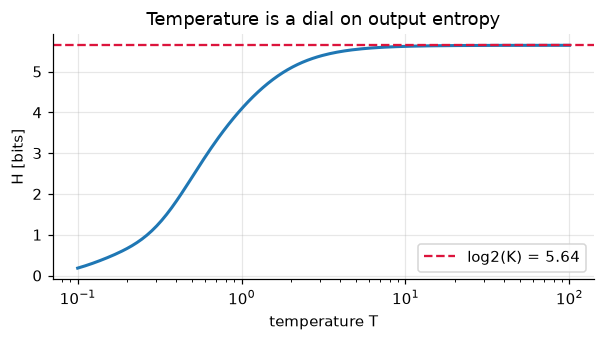

In [7]:
def softmax(z, T=1.0):
    z = np.asarray(z, float) / T
    z = z - z.max(axis=-1, keepdims=True)        # log-sum-exp shift, see Section 7
    e = np.exp(z)
    return e / e.sum(axis=-1, keepdims=True)

K = 50
logits = rng.normal(0, 2.0, size=K)

print(f"A single next-token distribution over K={K}, logits ~ N(0, 2^2)")
print(f"{'T':>7} {'H [bits]':>10} {'perplexity':>12} {'p(top-1)':>10} {'90% mass in':>12}")
for T in (0.1, 0.3, 0.5, 0.7, 1.0, 1.5, 2.0, 5.0, 100.0):
    q = softmax(logits, T)
    h = entropy(q)
    srt = np.sort(q)[::-1]
    n90 = int(np.searchsorted(np.cumsum(srt), 0.90) + 1)
    print(f"{T:>7.1f} {h:>10.4f} {2**h:>12.2f} {q.max():>10.4f} {n90:>9} tokens")
print()
print(f"Uniform over K={K} would be H = {np.log2(K):.4f} bits, perplexity {K:.1f}.")
print("T=100 has essentially reached it: the logits have been thrown away.")
print()
tops = {int(softmax(logits, T).argmax()) for T in (0.1, 0.3, 0.5, 0.7, 1.0, 1.5, 2.0, 5.0, 100.0)}
if len(tops) == 1:
    print("The argmax token is identical at every T above: temperature moved H from 0.18 to 5.64 bits")
    print("and p(top-1) from 0.97 to 0.02 without changing which token a greedy decoder would emit.")
    print("That is calibration moving while accuracy stands still — a loss and an error rate are")
    print("different quantities, and only one of them is what the 'perplexity' column measures.")
else:
    print(f"The argmax token changed across T ({len(tops)} distinct) — a tie in the logits; inspect before quoting.")

Ts = np.logspace(-1, 2, 200)
Hs = np.array([entropy(softmax(logits, T)) for T in Ts])
fig, ax = plt.subplots(figsize=(5.6, 3.2))
ax.semilogx(Ts, Hs, lw=2)
ax.axhline(np.log2(K), ls="--", c="crimson", label=f"log2(K) = {np.log2(K):.2f}")
ax.set_xlabel("temperature T"); ax.set_ylabel("H [bits]")
ax.set_title("Temperature is a dial on output entropy"); ax.legend()
plt.show()

---
## 3. Mutual information and the data-processing inequality

Mutual information is how much knowing $Y$ reduces your uncertainty about $X$:

$$I(X;Y) \;=\; H(X) - H(X\mid Y) \;=\; H(X) + H(Y) - H(X,Y) \;=\; D_{\mathrm{KL}}\!\left(p_{XY}\,\|\,p_X p_Y\right).$$

The last form is the one to remember: **mutual information is the KL divergence between the joint
and the product of the marginals** — literally a measurement of how far from independent two
variables are, in the same units as everything else.

The **data-processing inequality** follows: if $X \to Y \to Z$ is a Markov chain (so $Z$ depends on
$X$ only through $Y$), then

$$I(X;Z) \;\le\; I(X;Y).$$

Post-processing cannot create information. This is a hard constraint on every layer of every neural
network — a layer can destroy information about the input but never manufacture it — and it is the
formal reason the Information Bottleneck story in Section 5 is about *compression* rather than
*extraction*.

In [8]:
def mutual_information(joint):
    """I(X;Y) in bits from a joint PMF (2-D array)."""
    joint = np.asarray(joint, float); joint = joint / joint.sum()
    px = joint.sum(axis=1); py = joint.sum(axis=0)
    return entropy(px) + entropy(py) - entropy(joint.ravel())

# A correlated pair of bits with a tunable flip probability.
print("Binary symmetric channel: X uniform, Y = X flipped with probability f")
print(f"{'f':>6} {'I(X;Y) measured':>18} {'1 - H(f) exact':>16}")
for f in (0.0, 0.01, 0.1, 0.25, 0.5):
    J = np.array([[0.5 * (1 - f), 0.5 * f], [0.5 * f, 0.5 * (1 - f)]])
    exact = 1.0 - (-xlogx(f) - xlogx(1 - f)) if 0 < f < 1 else (1.0 if f == 0 else 0.0)
    print(f"{f:>6.2f} {mutual_information(J):>18.6f} {exact:>16.6f}")

# Data-processing inequality over random channels: X -> Y -> Z.
print("\nData-processing inequality, 5,000 random Markov chains X -> Y -> Z")
viol, gaps = 0, []
for _ in range(5000):
    nx, ny, nz = 4, 5, 3
    px = rng.dirichlet(np.ones(nx))
    Pyx = rng.dirichlet(np.ones(ny), size=nx)     # p(y|x)
    Pzy = rng.dirichlet(np.ones(nz), size=ny)     # p(z|y)
    Jxy = px[:, None] * Pyx
    Jxz = Jxy @ Pzy
    ixy, ixz = mutual_information(Jxy), mutual_information(Jxz)
    gaps.append(ixy - ixz)
    if ixz > ixy + 1e-12:
        viol += 1
gaps = np.array(gaps)
print(f"  violations: {viol} of 5000")
print(f"  I(X;Y) - I(X;Z):  min {gaps.min():.6f}   median {np.median(gaps):.4f}   max {gaps.max():.4f} bits")
print("  Every random post-processing step destroyed information. None created any.")

Binary symmetric channel: X uniform, Y = X flipped with probability f
     f    I(X;Y) measured   1 - H(f) exact
  0.00           1.000000         1.000000
  0.01           0.919207         0.919207
  0.10           0.531004         0.531004
  0.25           0.188722         0.188722
  0.50           0.000000         0.000000

Data-processing inequality, 5,000 random Markov chains X -> Y -> Z


  violations: 0 of 5000
  I(X;Y) - I(X;Z):  min 0.017982   median 0.2417   max 0.7243 bits
  Every random post-processing step destroyed information. None created any.


---
## 4. The plug-in estimator is biased, and the sign depends on the regime

This is the section to read if you read only one.

The formulas above take a *distribution* as input. In practice you have **samples**, and the obvious
move is to build a histogram, normalise it, and put it through the entropy formula. That is the
**plug-in** (or maximum-likelihood) estimator, and it is what almost every quick mutual-information
script does.

It is biased. Entropy is concave, so Jensen's inequality makes the plug-in entropy estimate
**too small**; mutual information is a difference of entropies arranged so that, to leading order on
a fixed $K\times L$ table with every cell probability positive and $N$ large,

$$\mathbb{E}[\hat{I}] - I \;\approx\; \frac{(K-1)(L-1)}{2N\ln 2}\ \text{bits} \;>\; 0.$$

The consequence is brutal and specific: **feed the estimator two completely independent variables,
where the true mutual information is exactly zero, and it will confidently report a positive
number.** Below we measure that number and compare it to the formula.

Then the correction to a rule you will see stated often, including by an earlier draft of this
notebook: "treat every mutual-information estimate as an upper bound." **That is not generally true.**
The leading-order term is positive, but it is a large-$N$ expansion on a table with no empty cells.
A strongly dependent pair observed on a sparse table under-counts its own dependence — with $X = Y$
a fair bit and a single sample, $\hat I = 0$ against a truth of 1 bit — while an independent pair on
a sparse table over-counts. The sign of the error depends on the distribution, the table and $N$,
and no single correction knows which case you are in. The honest instrument is a **permutation
null**: shuffle $Y$, re-estimate, repeat — the distribution of $\hat I$ under independence at *your*
$N$ and *your* bins.

TRUE mutual information is 0.000000 bits (X and Y drawn independently, 8x8 table)
       N   mean I_hat       std   predicted bias   ratio
      20     1.388577  0.193090         1.767301   0.786
      50     0.803480  0.108236         0.706921   1.137


     100     0.423092  0.067899         0.353460   1.197


     200     0.196598  0.038791         0.176730   1.112
     500     0.073725  0.015120         0.070692   1.043


    1000     0.035860  0.007079         0.035346   1.015


    5000     0.007059  0.001517         0.007069   0.999


   20000     0.001755  0.000342         0.001767   0.993


  100000     0.000347  0.000068         0.000353   0.981

measured / predicted:  0.786 to 1.197 over all N
                       0.981 to 1.197 for N >= 50
At N=20 the leading-order formula predicts 1.767 bits but the
estimator reports 1.389 — the asymptotic expansion is itself unreliable when the
table has fewer samples than cells, which is the regime it was derived to describe.


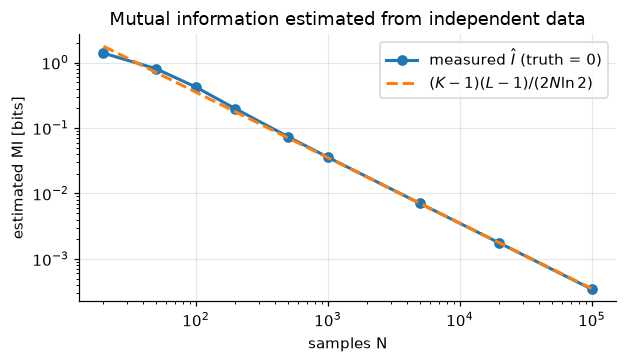

In [9]:
def plugin_mi_from_samples(x, y, kx, ky):
    J = np.zeros((kx, ky))
    np.add.at(J, (x, y), 1.0)
    return mutual_information(J)

KX, KY = 8, 8
Ns = [20, 50, 100, 200, 500, 1000, 5000, 20000, 100000]
TRIALS = 400

print(f"TRUE mutual information is 0.000000 bits (X and Y drawn independently, {KX}x{KY} table)")
print(f"{'N':>8} {'mean I_hat':>12} {'std':>9} {'predicted bias':>16} {'ratio':>7}")
rows = []
for N in Ns:
    est = np.empty(TRIALS)
    for t in range(TRIALS):
        x = rng.integers(0, KX, size=N); y = rng.integers(0, KY, size=N)
        est[t] = plugin_mi_from_samples(x, y, KX, KY)
    pred = (KX - 1) * (KY - 1) / (2 * N * np.log(2))
    rows.append((N, est.mean(), est.std(), pred))
    print(f"{N:>8} {est.mean():>12.6f} {est.std():>9.6f} {pred:>16.6f} {est.mean()/pred:>7.3f}")

rows = np.array(rows)
ratios = rows[:, 1] / rows[:, 3]
big = rows[:, 0] >= 50
print()
print(f"measured / predicted:  {ratios.min():.3f} to {ratios.max():.3f} over all N")
print(f"                       {ratios[big].min():.3f} to {ratios[big].max():.3f} for N >= 50")
print(f"At N={int(rows[0,0])} the leading-order formula predicts {rows[0,3]:.3f} bits but the")
print(f"estimator reports {rows[0,1]:.3f} — the asymptotic expansion is itself unreliable when the")
print("table has fewer samples than cells, which is the regime it was derived to describe.")

fig, ax = plt.subplots(figsize=(5.8, 3.4))
ax.loglog(rows[:, 0], rows[:, 1], "o-", lw=2, label=r"measured $\hat{I}$ (truth = 0)")
ax.loglog(rows[:, 0], rows[:, 3], "--", lw=2, label=r"$(K-1)(L-1)/(2N\ln 2)$")
ax.set_xlabel("samples N"); ax.set_ylabel("estimated MI [bits]")
ax.set_title("Mutual information estimated from independent data")
ax.legend()
plt.show()

In [10]:
# How bad is it in the regime people actually use?
N = 200
print(f"At N={N} samples on an {KX}x{KY} table, the estimator reports about "
      f"{rows[Ns.index(N), 1]:.3f} bits of mutual information between two independent variables.")
print(f"For scale, a perfectly informative binary variable carries 1.000 bits.")
print()
print("Now the same experiment with a *real* dependency, to show the bias does not cancel out:")
print(f"{'N':>8} {'true I':>9} {'I_hat':>9} {'error':>9}")
f = 0.1
Jtrue = np.array([[0.5 * (1 - f), 0.5 * f], [0.5 * f, 0.5 * (1 - f)]])
Itrue = mutual_information(Jtrue)
for N in (50, 200, 1000, 10000):
    est = []
    for _ in range(400):
        x = rng.integers(0, 2, size=N)
        flip = rng.random(N) < f
        y = np.where(flip, 1 - x, x)
        est.append(plugin_mi_from_samples(x, y, 2, 2))
    m = np.mean(est)
    print(f"{N:>8} {Itrue:>9.5f} {m:>9.5f} {m - Itrue:>+9.5f}")
print()
print("Smaller table, smaller bias — still positive in expectation at every N, but by")
print("N=10,000 the bias is below what 400 trials resolve, so the last row prints negative.")
print("Practical rule: the plug-in estimator needs N >> K*L, and 'differences of MI' between")
print("two setups are only comparable when their table sizes and sample counts match exactly.")

At N=200 samples on an 8x8 table, the estimator reports about 0.197 bits of mutual information between two independent variables.
For scale, a perfectly informative binary variable carries 1.000 bits.

Now the same experiment with a *real* dependency, to show the bias does not cancel out:
       N    true I     I_hat     error
      50   0.53100   0.54576  +0.01476
     200   0.53100   0.53917  +0.00817
    1000   0.53100   0.53184  +0.00084


   10000   0.53100   0.53096  -0.00004

Smaller table, smaller bias — still positive in expectation at every N, but by
N=10,000 the bias is below what 400 trials resolve, so the last row prints negative.
Practical rule: the plug-in estimator needs N >> K*L, and 'differences of MI' between
two setups are only comparable when their table sizes and sample counts match exactly.


In [11]:
# The sign is not fixed. A perfectly dependent pair, X = Y, has I = 1 bit exactly. Observe it on a
# sparse table and the plug-in estimate reads LOW: with one sample the empirical joint is a single
# cell and every entropy in the formula is zero.
r_sign = np.random.default_rng(20261008)                # own stream, so later cells are unaffected
print("X = Y, a fair bit: TRUE I(X;Y) = 1.000000 bits — the same estimator, now under-counting")
print(f"{'N':>6} {'mean I_hat':>12} {'error':>10}")
signs = []
for N in (1, 2, 3, 5, 10, 30, 100):
    est = np.empty(2000)
    for t in range(2000):
        x = r_sign.integers(0, 2, size=N)
        est[t] = plugin_mi_from_samples(x, x, 2, 2)
    signs.append(est.mean() - 1.0)
    print(f"{N:>6} {est.mean():>12.6f} {est.mean()-1.0:>+10.6f}")
print()
if signs[0] < -0.9 and signs[-1] > -0.05:
    print("Under-estimate by a full bit at N=1, by half a bit at N=2, converging upward — the")
    print("opposite sign from the independence table above. There is no 'upper bound' here.")
else:
    print("Unexpected shape — inspect before quoting any sign claim.")

# The null that matters: your N, your bins. Shuffle Y and re-estimate.
N = 200
x = r_sign.integers(0, KX, size=N); y = r_sign.integers(0, KY, size=N)     # independent by construction
obs = plugin_mi_from_samples(x, y, KX, KY)
null = np.array([plugin_mi_from_samples(x, r_sign.permutation(y), KX, KY) for _ in range(2000)])
p95, p99 = np.percentile(null, 95), np.percentile(null, 99)
print()
print(f"Permutation null at N={N} on an {KX}x{KY} table (2,000 shuffles of Y):")
print(f"  observed I_hat = {obs:.4f} bits;  null 95th percentile = {p95:.4f};  99th = {p99:.4f}")
if obs < p95:
    print("  The observed value sits inside the null: at this N and this binning, it is not")
    print("  distinguishable from independence — which is what it is.")
else:
    print("  The observed value exceeds the 95th percentile of the null for an independent pair;")
    print("  that happens about 1 time in 20 and this is one of them. Re-run with another seed.")
print("  This null costs 2,000 estimator calls and replaces a formula that fails at small N.")

X = Y, a fair bit: TRUE I(X;Y) = 1.000000 bits — the same estimator, now under-counting
     N   mean I_hat      error


     1     0.000000  -1.000000


     2     0.487500  -0.512500


     3     0.695150  -0.304850


     5     0.826845  -0.173155


    10     0.922680  -0.077320


    30     0.976193  -0.023807


   100     0.992434  -0.007566

Under-estimate by a full bit at N=1, by half a bit at N=2, converging upward — the
opposite sign from the independence table above. There is no 'upper bound' here.



Permutation null at N=200 on an 8x8 table (2,000 shuffles of Y):
  observed I_hat = 0.2286 bits;  null 95th percentile = 0.2650;  99th = 0.3012
  The observed value sits inside the null: at this N and this binning, it is not
  distinguishable from independence — which is what it is.
  This null costs 2,000 estimator calls and replaces a formula that fails at small N.


---
## 5. The information plane

[Tishby & Zaslavsky (arXiv:1503.02406)](https://arxiv.org/abs/1503.02406) proposed reading a deep
network as a chain of successive compressions, and
[Shwartz-Ziv & Tishby (arXiv:1703.00810)](https://arxiv.org/abs/1703.00810) produced the picture the
idea is famous for: plot each hidden layer as a point $(I(T;X),\,I(T;Y))$ and watch it move during
training. The reported behaviour is two phases — a short **fitting** phase where both quantities
rise, then a long **compression** phase where $I(T;X)$ *falls* while $I(T;Y)$ stays flat. The network
is said to be forgetting the parts of the input that do not matter.

[Saxe et al. (ICLR 2018)](https://openreview.net/forum?id=ry_WPG-A-) disputed this, arguing that the
compression phase is largely an artefact of using **saturating** nonlinearities and of estimating
mutual information by **binning** activations.

This is a rare argument where a laptop can at least settle what the *measurement* is, so we do it.
We build the setup where $I(T;X)$ is *exactly* computable rather than estimated: a deterministic
network on a **finite, uniform** input distribution. With $X$ uniform over $2^{12}=4096$ patterns and
$T$ a deterministic function of $X$, $I(T;X) = H(T) \le H(X) = 12$ bits, exactly — no sampling, no
estimator bias, and **no infinity anywhere**. The familiar line "$I(T;X)$ is infinite for a
deterministic network" is true for a continuous input distribution and false for this one; the first
version of this notebook said it anyway, and it was wrong for its own experiment. The exact value is
computed below by counting distinct activation vectors. The *binned* value — $H$ of the activation
vector after each unit is quantised to 30 levels — is a different, smaller number, and it measures
how tightly the layer clusters its activations, which is a geometric property, not an
information-theoretic one ([Goldfeld et al., 2019](https://arxiv.org/abs/1810.05728)). All the
fragility therefore sits in one place, the binning, and we vary it on purpose.

**The status of the claim, stated rather than implied.** The fitting-then-compression story is not
the current default explanation of deep training. Outside saturating nonlinearities the compression
phase is generally not observed (Saxe et al.); with noise injected so that $I(X;T)$ is finite and
estimable, the measured quantity tracks geometric clustering (Goldfeld et al.); and the live
alternatives — [neural collapse](https://arxiv.org/abs/2008.08186),
[grokking](https://arxiv.org/abs/2201.02177), geometric accounts of representation learning — do not
require an information-theoretic phase at all. One notebook with one pair of networks is an
illustration, not a settlement.

The network is a 12→10→7→5→4→3→2 MLP with hand-written forward and backward passes, trained with
full-batch gradient descent on a balanced binary task. We train the identical architecture twice:
once with `tanh`, once with `ReLU`.

> **An error worth keeping.** The first run of this notebook initialised both networks at
> $1/\sqrt{\text{fan-in}}$. That is right for `tanh` and wrong for `ReLU`, which discards half its
> input variance; through six layers the signal died and the ReLU network sat at chance accuracy
> (0.5002) for all 4,000 epochs. Its information plane looked beautifully uncompressed — because
> nothing had happened. **A comparison between a trained network and an untrained one will happily
> produce a publishable-looking difference.** The cell below therefore asserts that both networks
> actually fit the task before any conclusion is drawn from them.

In [12]:
# ---- dataset: all 4096 twelve-bit patterns, balanced binary label ----
NBITS = 12
X = ((np.arange(2**NBITS)[:, None] >> np.arange(NBITS)[::-1]) & 1).astype(float)
w_true = rng.normal(size=NBITS)
score = X @ w_true
Y = (score > np.median(score)).astype(int)          # exactly balanced by construction
Y1h = np.eye(2)[Y]

print(f"X: {X.shape}  (all {2**NBITS} patterns, each with probability 2^-{NBITS})")
print(f"Y balance: {Y.mean():.4f}   H(Y) = {entropy(np.bincount(Y)/len(Y)):.6f} bits")

LAYERS = [NBITS, 10, 7, 5, 4, 3, 2]

def init_params(seed, act):
    """
    Gain matters. ReLU halves the variance of whatever passes through it, so a network
    initialised at 1/sqrt(fan_in) — correct for tanh — loses signal at every layer and,
    in a funnel this narrow, never starts training at all. He initialisation puts the
    sqrt(2) back. The first version of this notebook omitted it and the ReLU run sat at
    chance accuracy for 4,000 epochs; see the note under Section 5.
    """
    r = np.random.default_rng(seed)
    gain = np.sqrt(2.0) if act == "relu" else 1.0
    return [(r.normal(0, gain/np.sqrt(a), (a, b)), np.zeros(b))
            for a, b in zip(LAYERS[:-1], LAYERS[1:])]

def forward(params, x, act):
    """Returns (list of hidden activations, output probabilities)."""
    h, hs = x, []
    for i, (W, b) in enumerate(params):
        z = h @ W + b
        if i < len(params) - 1:
            h = np.tanh(z) if act == "tanh" else np.maximum(z, 0.0)
            hs.append(h)
        else:
            h = softmax(z)
    return hs, h

def backward(params, x, y1h, act):
    """Hand-derived gradients for softmax + cross-entropy."""
    zs, hs, h = [], [], x
    for i, (W, b) in enumerate(params):
        z = h @ W + b; zs.append(z)
        h = (np.tanh(z) if act == "tanh" else np.maximum(z, 0.0)) if i < len(params) - 1 else softmax(z)
        hs.append(h)
    N = x.shape[0]
    delta = (hs[-1] - y1h) / N                      # dL/dz for softmax+CE, in nats
    grads = [None] * len(params)
    for i in range(len(params) - 1, -1, -1):
        h_prev = x if i == 0 else hs[i - 1]
        grads[i] = (h_prev.T @ delta, delta.sum(axis=0))
        if i > 0:
            dh = delta @ params[i][0].T
            delta = dh * (1 - np.tanh(zs[i-1])**2) if act == "tanh" else dh * (zs[i-1] > 0)
    loss = -np.mean(np.sum(y1h * np.log(np.clip(hs[-1], 1e-300, None)), axis=1))
    return grads, loss

X: (4096, 12)  (all 4096 patterns, each with probability 2^-12)
Y balance: 0.5000   H(Y) = 1.000000 bits


In [13]:
# ---- gradient check against finite differences (the notebook's own unit test) ----
# Checked on a weight whose gradient is actually non-negligible: a zero-vs-zero match
# is not evidence that the backward pass is right, and with ReLU it is easy to land on
# a dead unit and mistake silence for agreement.
eps = 1e-6
for act in ("tanh", "relu"):
    P = init_params(7, act)
    g, _ = backward(P, X[:64], Y1h[:64], act)
    checked = 0
    for li in range(len(P)):
        cand = np.argwhere(np.abs(g[li][0]) > 1e-5)
        if len(cand) == 0:
            print(f"{act:>5}: layer {li} has no gradient above 1e-5 — skipped"); continue
        i, j = cand[0]
        Pp = [(W.copy(), b.copy()) for W, b in P]; Pp[li][0][i, j] += eps
        Pm = [(W.copy(), b.copy()) for W, b in P]; Pm[li][0][i, j] -= eps
        fd = (backward(Pp, X[:64], Y1h[:64], act)[1] - backward(Pm, X[:64], Y1h[:64], act)[1]) / (2 * eps)
        rel = abs(g[li][0][i, j] - fd) / max(abs(fd), 1e-12)
        print(f"{act:>5} layer {li}: analytic {g[li][0][i,j]:+.9f}   finite-diff {fd:+.9f}   rel.err {rel:.2e}")
        assert rel < 1e-5, f"backward pass disagrees with finite differences ({act}, layer {li})"
        checked += 1
    print(f"{act:>5}: {checked} layers checked, all within 1e-5 relative error\n")

 tanh layer 0: analytic +0.012584115   finite-diff +0.012584115   rel.err 1.60e-09
 tanh layer 1: analytic -0.000101727   finite-diff -0.000101727   rel.err 5.44e-07
 tanh layer 2: analytic -0.000322503   finite-diff -0.000322503   rel.err 5.65e-08
 tanh layer 3: analytic -0.004054836   finite-diff -0.004054836   rel.err 1.81e-08
 tanh layer 4: analytic +0.000077262   finite-diff +0.000077262   rel.err 2.48e-07
 tanh layer 5: analytic +0.038125387   finite-diff +0.038125387   rel.err 2.73e-10
 tanh: 6 layers checked, all within 1e-5 relative error

 relu layer 0: analytic +0.000206275   finite-diff +0.000206275   rel.err 6.18e-08
 relu layer 1: analytic +0.000037443   finite-diff +0.000037443   rel.err 2.18e-07
 relu layer 2: analytic -0.000059327   finite-diff -0.000059327   rel.err 3.81e-07
 relu layer 3: analytic -0.000149494   finite-diff -0.000149494   rel.err 2.73e-07
 relu layer 4: analytic -0.000044986   finite-diff -0.000044986   rel.err 1.85e-07
 relu layer 5: analytic -0.000

In [14]:
def layer_information(h, Y, nbins, act):
    """
    Exact I(T;X) and I(T;Y) for a deterministic net on a uniform finite input set.
    T = binned activation vector.  I(T;X) = H(T);  I(T;Y) = H(Y) - H(Y|T).
    """
    lo, hi = (-1.0, 1.0) if act == "tanh" else (0.0, max(h.max(), 1e-12))
    edges = np.linspace(lo, hi, nbins + 1)[1:-1]
    idx = np.digitize(h, edges)                                  # (N, d) bin indices
    # unique row -> cluster id
    _, tid = np.unique(idx, axis=0, return_inverse=True)
    n = len(tid)
    pT = np.bincount(tid) / n
    ITX = entropy(pT)                                            # exact: X uniform, T deterministic
    J = np.zeros((pT.size, 2)); np.add.at(J, (tid, Y), 1.0 / n)
    ITY = mutual_information(J)
    return ITX, ITY, pT.size

def train_and_track(act, epochs=4000, lr=0.6, nbins=30, seed=7):
    P = init_params(seed, act)
    track, losses = [], []
    probe = sorted(set(np.unique(np.round(np.logspace(0, np.log10(epochs), 90)).astype(int))))
    for ep in range(1, epochs + 1):
        g, L = backward(P, X, Y1h, act)
        P = [(W - lr * gW, b - lr * gb) for (W, b), (gW, gb) in zip(P, g)]
        losses.append(L)
        if ep in probe:
            hs, out = forward(P, X, act)
            acc = (out.argmax(1) == Y).mean()
            info = [layer_information(h, Y, nbins, act)[:2] for h in hs]
            # the EXACT per-layer quantities at the same checkpoint, from the same forward pass: distinct
            # activation vectors (so H(T) exactly) and the fraction of constant units. Recorded here so that
            # one pair of fitted networks supplies the whole trajectory and no second training run is needed.
            exact = []
            for h in hs:
                _, inv = np.unique(h, axis=0, return_inverse=True)
                n_distinct = int(inv.max()) + 1
                exact.append((n_distinct, entropy(np.bincount(inv) / len(inv)), float((h.std(axis=0) < 1e-12).mean())))
            track.append((ep, acc, L, info, exact))
    return P, track, losses

res = {}
for act in ("tanh", "relu"):
    P, track, losses = train_and_track(act)
    res[act] = (P, track, losses)
    ep, acc, L = track[-1][:3]
    print(f"{act:>5}: final epoch {ep}  loss {L:.5f} nats  train accuracy {acc:.4f}")

# The comparison in this section is only meaningful if BOTH networks actually fit the task.
# Comparing a trained net against an untrained one would show a difference in compression
# that is really just a difference in whether learning happened.
for act in ("tanh", "relu"):
    acc = res[act][1][-1][1]
    assert acc > 0.95, f"{act} network did not fit the task (accuracy {acc:.4f}) — comparison invalid"
print("\nBoth networks fit the task, so differences below are about the nonlinearity, not about training.")

hs_relu, _ = forward(res["relu"][0], X, "relu")
dead = [float((h <= 0).all(axis=0).mean()) for h in hs_relu]
print(f"Permanently dead ReLU units by layer: {[f'{d:.0%}' for d in dead]}")
print("Dead units are information destruction in the most literal form available: a unit that")
print("outputs zero for all 4,096 inputs carries no bits about any of them.")

 tanh: final epoch 4000  loss 0.00008 nats  train accuracy 1.0000


 relu: final epoch 4000  loss 0.03921 nats  train accuracy 0.9890

Both networks fit the task, so differences below are about the nonlinearity, not about training.
Permanently dead ReLU units by layer: ['0%', '0%', '40%', '25%', '67%']
Dead units are information destruction in the most literal form available: a unit that
outputs zero for all 4,096 inputs carries no bits about any of them.


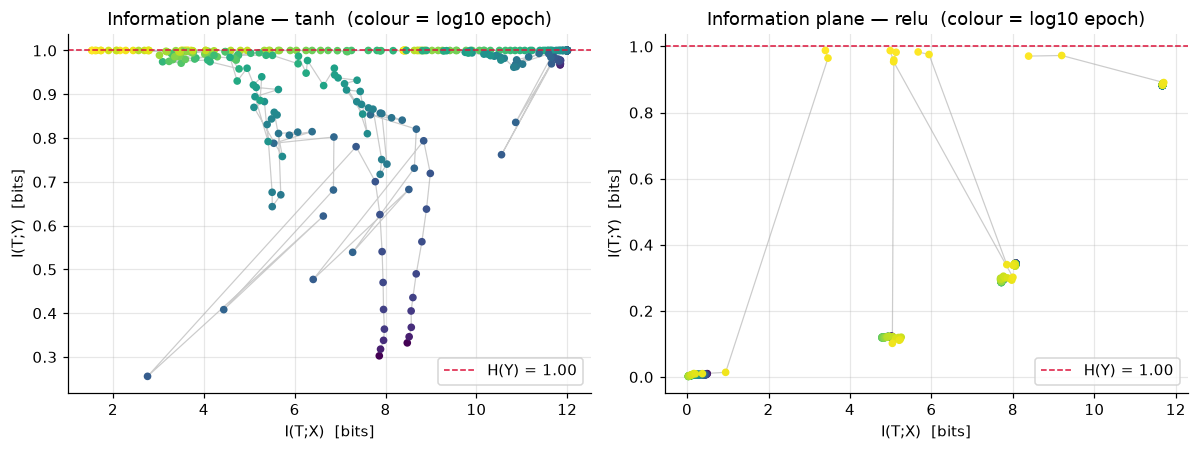

Per-layer I(T;X): value at its peak, and at the end of training (30 bins)
  act  layer  peak I(T;X)     final    change
 tanh      1      12.0000   11.9893   -0.0107
 tanh      2      12.0000    8.4147   -3.5853
 tanh      3      11.8529    3.6580   -8.1948
 tanh      4       8.9857    2.0854   -6.9003
 tanh      5       7.9751    1.5376   -6.4375
 relu      1      11.7029    8.3856   -3.3173
 relu      2       8.0739    5.6741   -2.3998
 relu      3       8.0004    4.9885   -3.0119
 relu      4       5.2580    5.1328   -0.1252
 relu      5       3.4599    3.3971   -0.0628


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
HY = entropy(np.bincount(Y) / len(Y))
for ax, act in zip(axes, ("tanh", "relu")):
    track = res[act][1]
    nL = len(track[0][3])
    cmap = plt.cm.viridis
    for li in range(nL):
        xs = [t[3][li][0] for t in track]
        ys = [t[3][li][1] for t in track]
        cs = [np.log10(t[0]) for t in track]
        ax.plot(xs, ys, "-", c="0.8", lw=0.8, zorder=1)
        ax.scatter(xs, ys, c=cs, cmap=cmap, s=16, zorder=2)
    ax.axhline(HY, ls="--", c="crimson", lw=1, label=f"H(Y) = {HY:.2f}")
    ax.set_xlabel("I(T;X)  [bits]"); ax.set_ylabel("I(T;Y)  [bits]")
    ax.set_title(f"Information plane — {act}  (colour = log10 epoch)")
    ax.legend(loc="lower right")
plt.show()

print("Per-layer I(T;X): value at its peak, and at the end of training (30 bins)")
print(f"{'act':>5} {'layer':>6} {'peak I(T;X)':>12} {'final':>9} {'change':>9}")
for act in ("tanh", "relu"):
    track = res[act][1]
    for li in range(len(track[0][3])):
        series = np.array([t[3][li][0] for t in track])
        print(f"{act:>5} {li+1:>6} {series.max():>12.4f} {series[-1]:>9.4f} {series[-1]-series.max():>+9.4f}")

In [16]:
# Does the conclusion survive a change of bin count?  This is the Saxe et al. objection, measured.
print("Final-epoch I(T;X) of the deepest hidden layer, as a function of bin count")
print(f"{'bins':>6} {'tanh':>10} {'relu':>10}")
for nb in (8, 16, 30, 60, 120, 256):
    row = []
    for act in ("tanh", "relu"):
        P = res[act][0]
        hs, _ = forward(P, X, act)
        row.append(layer_information(hs[-1], Y, nb, act)[0])
    print(f"{nb:>6} {row[0]:>10.4f} {row[1]:>10.4f}")
print()
print(f"For reference, H(X) = {NBITS:.4f} bits — the hard ceiling on I(T;X), and for this finite-support")
print("input the EXACT value of I(T;X) = H(T) is computed in the next cell with no binning at all.")
print("The binned numbers move with the bin count and climb toward that exact value as the bins shrink.")
print("So every finite number above is a property of the discretisation as much as of the network;")
print("it measures how tightly the layer clusters its activations, not an information quantity.")
print("(For a CONTINUOUS input distribution the exact I(T;X) of a deterministic net would be infinite —")
print(" a different probability model from the one this experiment uses.)")

Final-epoch I(T;X) of the deepest hidden layer, as a function of bin count
  bins       tanh       relu
     8     1.2124     2.1748
    16     1.3296     2.8675
    30     1.5376     3.3971
    60     1.6883     3.9717
   120     1.7661     4.5322
   256     2.3442     5.1362

For reference, H(X) = 12.0000 bits — the hard ceiling on I(T;X), and for this finite-support
input the EXACT value of I(T;X) = H(T) is computed in the next cell with no binning at all.
The binned numbers move with the bin count and climb toward that exact value as the bins shrink.
So every finite number above is a property of the discretisation as much as of the network;
it measures how tightly the layer clusters its activations, not an information quantity.
(For a CONTINUOUS input distribution the exact I(T;X) of a deterministic net would be infinite —
 a different probability model from the one this experiment uses.)


In [17]:
# The exact quantity, with no estimator. X has finite support (4,096 equiprobable points) and T is a
# deterministic function of X, so I(X;T) = H(T) exactly, with T the activation vector at float64
# precision (NumPy's default dtype — nothing in this notebook is float32). H(T) is the entropy of the
# empirical distribution over DISTINCT activation vectors;
# it equals 12 bits iff every input maps to its own vector. Beside it: the 30-bin value, the
# effective rank of the layer's activation covariance (a binning-free geometry measure), and the
# fraction of units that are constant on the whole input set.
def effective_rank(h):
    hc = h - h.mean(axis=0)
    lam = np.linalg.eigvalsh(np.atleast_2d(hc.T @ hc / len(hc)))
    lam = np.clip(lam, 0, None)
    if lam.sum() <= 0: return 0.0
    p = lam / lam.sum()
    return float(np.exp(-np.sum(p[p > 0] * np.log(p[p > 0]))))

print("Exact I(X;T) = H(T) at float64 precision (the dtype the network was trained and read in), final epoch, vs the 30-bin value")
print(f"{'act':>5} {'layer':>6} {'width':>6} {'distinct':>9} {'H(T) exact':>11} {'30-bin':>8} {'eff.rank':>9} {'const units':>12}")
exact = {}
for act in ("tanh", "relu"):
    hs, _ = forward(res[act][0], X, act)
    for li, h in enumerate(hs):
        _, inv = np.unique(h, axis=0, return_inverse=True)
        pT = np.bincount(inv) / len(inv)
        Hex = entropy(pT)
        binned = layer_information(h, Y, 30, act)[0]
        const = float((h.std(axis=0) < 1e-12).mean())
        exact[(act, li)] = (len(pT), Hex)
        print(f"{act:>5} {li+1:>6} {h.shape[1]:>6} {len(pT):>9} {Hex:>11.4f} {binned:>8.4f} {effective_rank(h):>9.3f} {const:>11.0%}")
print()
full = [k for k, (n_, H_) in exact.items() if n_ == 2**NBITS]
short = [k for k, (n_, H_) in exact.items() if n_ < 2**NBITS]
if not short:
    print("Every layer of both networks maps all 4,096 inputs to 4,096 distinct vectors: H(T) = 12 bits")
    print("everywhere. The exact information plane of this experiment is a single point that never moves.")
else:
    print(f"{len(full)} of {len(exact)} layers keep all 4,096 inputs distinct (H(T) = 12 bits exactly).")
    for (act, li) in short:
        n_, H_ = exact[(act, li)]
        print(f"  {act} layer {li+1}: {n_} distinct vectors, H(T) = {H_:.4f} bits — this layer genuinely")
        print(f"  merges inputs (constant/dead units and clipping), and THAT is a real information loss.")
    print("Everywhere else the exact value is the ceiling, and every number below it in the earlier")
    print("tables is a statement about clustering under a quantiser, not about I(X;T).")
print()
print("Lead with the dead-unit fraction and the effective rank when you tell the story: neither needs")
print("a bin count, and the ReLU network's deepest layers are losing capacity, not learning to be selective.")

Exact I(X;T) = H(T) at float64 precision (the dtype the network was trained and read in), final epoch, vs the 30-bin value
  act  layer  width  distinct  H(T) exact   30-bin  eff.rank  const units


 tanh      1     10      4096     12.0000  11.9893     2.441          0%
 tanh      2      7      4096     12.0000   8.4147     1.186          0%
 tanh      3      5      4096     12.0000   3.6580     1.053          0%
 tanh      4      4      4096     12.0000   2.0854     1.030          0%
 tanh      5      3      4096     12.0000   1.5376     1.026          0%
 relu      1     10      4096     12.0000   8.3856     1.717          0%
 relu      2      7      4096     12.0000   5.6741     1.572          0%


 relu      3      5      4065     11.9609   4.9885     1.313         40%


 relu      4      4      4065     11.9609   5.1328     1.537         25%
 relu      5      3      2271      7.2237   3.3971     1.000         67%

7 of 10 layers keep all 4,096 inputs distinct (H(T) = 12 bits exactly).
  relu layer 3: 4065 distinct vectors, H(T) = 11.9609 bits — this layer genuinely
  merges inputs (constant/dead units and clipping), and THAT is a real information loss.
  relu layer 4: 4065 distinct vectors, H(T) = 11.9609 bits — this layer genuinely
  merges inputs (constant/dead units and clipping), and THAT is a real information loss.
  relu layer 5: 2271 distinct vectors, H(T) = 7.2237 bits — this layer genuinely
  merges inputs (constant/dead units and clipping), and THAT is a real information loss.
Everywhere else the exact value is the ceiling, and every number below it in the earlier
tables is a statement about clustering under a quantiser, not about I(X;T).

Lead with the dead-unit fraction and the effective rank when you tell the story: neither needs
a bin co

In [18]:
# The precision is part of the measurement. Every array above is float64 (NumPy's default), so "distinct
# activation vectors" means distinct AS FLOAT64. A consumer that reads the layer at lower precision reads a
# DIFFERENT map, and the exact count has to be redone for that map. The rows below are readout casts of the
# float64-trained representation — the same weights, the same forward pass, then a cast — not separately
# trained float32 or float16 networks (training at lower precision would change the weights as well).
print("Readout-precision ablation: distinct activation vectors and H(T) [bits] when the float64 activations")
print("are CAST to a narrower dtype before counting (same trained weights; the cast is at the readout only).")
print(f"{'act':>5} {'layer':>6} | {'float64':>18} | {'float32 cast':>18} | {'float16 cast':>18}")
dtype_ablation = {}
for act in ("tanh", "relu"):
    hs, _ = forward(res[act][0], X, act)
    for li, h in enumerate(hs):
        cells = []
        for dt in (np.float64, np.float32, np.float16):
            hc = h.astype(dt)
            _, inv = np.unique(hc, axis=0, return_inverse=True)
            pT = np.bincount(inv) / len(inv)
            dtype_ablation[(act, li, np.dtype(dt).name)] = (len(pT), entropy(pT))
            cells.append(f"{len(pT):>6} {entropy(pT):>10.4f}")
        print(f"{act:>5} {li+1:>6} | " + " | ".join(cells))
print()
print("For a deterministic map on a finite input set, I(X;T) = H(T) is exact at EVERY precision; what the cast")
print("changes is the map whose entropy is being counted. Quote the first column as 'float64', and do not read")
print("it as what an FP32 or FP16 consumer of the layer would see — that is the column for that consumer.")

# Save the trained parameters, so the published representation can be evaluated without retraining.
# Retraining on another platform (other Python / NumPy / BLAS) can land on different weights from the same
# seed, and the exact collision counts are sensitive to that; a forward pass from saved weights is not.
import os
_arrays = {**{f"{act}_W{i}": W for act in ("tanh", "relu") for i, (W, b) in enumerate(res[act][0])},
           **{f"{act}_b{i}": b for act in ("tanh", "relu") for i, (W, b) in enumerate(res[act][0])}}
_np = sum(W.size + b.size for act in ("tanh", "relu") for (W, b) in res[act][0])
np.savez("nb00_trained_params.local.npz", **_arrays)
print(f"saved nb00_trained_params.local.npz: THIS run's weights, both networks, {_np} parameters, float64")
REF = "nb00_trained_params.npz"     # the published reference weights, shipped beside the notebook; never overwritten here
REF_SHA256 = "5658302822b3fb7815e7b3443a93aa287cea137ddc673ac0c9b907bb400a1690"   # released checksum (nb00_trained_params.sha256)
if os.path.exists(REF):
    import hashlib
    _sha = hashlib.sha256(open(REF, "rb").read()).hexdigest()
    print(f"published reference {REF} found; its SHA-256 {_sha[:16]}... {'MATCHES' if _sha == REF_SHA256 else 'DOES NOT MATCH'} the released checksum {REF_SHA256[:16]}...")
    if _sha != REF_SHA256:
        print("  -> the file beside this notebook is not the released reference; a match below is NOT a reproduction of the published tables.")
    ref = np.load(REF)
    same_ref = all(k in ref.files and np.array_equal(ref[k], v) for k, v in _arrays.items())
    print(f"this run's weights identical to the reference file: {same_ref}")
    if not same_ref:
        print("  (another platform / BLAS can land on different weights from the same seed. The published tables")
        print("   describe the REFERENCE weights; their exact per-layer distinct-vector counts, for comparison:)")
        for act in ("tanh", "relu"):
            Pref = [(ref[f"{act}_W{i}"], ref[f"{act}_b{i}"]) for i in range(len(res[act][0]))]
            hs_ref, _ = forward(Pref, X, act)
            print(f"   {act}: {[int(np.unique(h, axis=0).shape[0]) for h in hs_ref]}  (this run: {[int(np.unique(h, axis=0).shape[0]) for h in forward(res[act][0], X, act)[0]]})")
else:
    print(f"no published reference {REF} beside this notebook: continuing on this run's weights (nb00_trained_params.local.npz).")
    print("  The reference is NOT created here — a locally trained file must never become the canonical one by accident, and a")
    print("  later 'identical to the reference' line would then be self-confirmation, not reproduction. The reference is produced")
    print(f"  only by the explicit release step `python make_reference_weights.py --write`, which records its SHA-256 ({REF_SHA256[:16]}...).")

Readout-precision ablation: distinct activation vectors and H(T) [bits] when the float64 activations
are CAST to a narrower dtype before counting (same trained weights; the cast is at the readout only).
  act  layer |            float64 |       float32 cast |       float16 cast
 tanh      1 |   4096    12.0000 |   4096    12.0000 |   4096    12.0000
 tanh      2 |   4096    12.0000 |   4096    12.0000 |   4095    11.9995
 tanh      3 |   4096    12.0000 |   4096    12.0000 |   2990    11.1031
 tanh      4 |   4096    12.0000 |   4096    12.0000 |   1234     8.1140


 tanh      5 |   4096    12.0000 |   4090    11.9971 |    445     4.2910


 relu      1 |   4096    12.0000 |   4096    12.0000 |   4095    11.9995


 relu      2 |   4096    12.0000 |   4096    12.0000 |   3630    11.7501
 relu      3 |   4065    11.9609 |   4065    11.9609 |   3565    11.6983
 relu      4 |   4065    11.9609 |   4065    11.9609 |   3154    11.4652


 relu      5 |   2271     7.2237 |   2271     7.2237 |   1473     6.7696

For a deterministic map on a finite input set, I(X;T) = H(T) is exact at EVERY precision; what the cast
changes is the map whose entropy is being counted. Quote the first column as 'float64', and do not read
it as what an FP32 or FP16 consumer of the layer would see — that is the column for that consumer.
saved nb00_trained_params.local.npz: THIS run's weights, both networks, 588 parameters, float64
published reference nb00_trained_params.npz found; its SHA-256 5658302822b3fb78... MATCHES the released checksum 5658302822b3fb78...
this run's weights identical to the reference file: True


### 5.1 Two more legs: when the collisions appear, and the stochastic representation

Two things the final-epoch table cannot answer. **When** did the ReLU layers start merging inputs
— and did it happen where the units died, or somewhere else? And what does the experiment look like
for a representation that is *not* deterministic? The first is answered by the exact per-layer count
that the training pass above recorded at every probe epoch, from the same forward pass as the binned
value — one pair of fitted networks supplies the whole trajectory, and no second training run is needed. The second adds Gaussian noise of a
stated variance to the activations. Because $X$ has finite support, $I(X;\,T+N)$ needs **no
estimator**: $p(\tilde t)$ is a 4,096-component Gaussian mixture with known components, so the
mutual information is an ordinary Monte Carlo expectation of $\log p(\tilde t\mid x) - \log p(\tilde t)$,
with a standard error and no bins, no batch-size ceiling and no critic. As $\sigma\to 0$ it tends to the
exact $H(T)$ above; as $\sigma\to\infty$ it tends to zero.

The noisy leg is run twice. Once with the **same absolute** $\sigma$ on both networks — the comparison
at the scale each network actually produced — and once on **scale-normalised** activations,
$I\big(X;\,T/\mathrm{RMS}(T) + \sigma Z\big)$, so that $\sigma$ is a fraction of each layer's own RMS.
A downstream affine layer can absorb a rescaling of its inputs for free, so the second table is the one
that survives an arbitrary change of activation scale; where the two tables disagree, the disagreement
is scale and not shape.

In [19]:
import time   # used by the noisy-readout cells below
# The exact per-checkpoint quantities were recorded during the SAME training pass that produced the
# final-epoch table (train_and_track computes them from the same forward pass as the binned values at
# every probe epoch), so one pair of fitted networks supplies the whole trajectory. Consistency check:
# the final probe's exact counts must equal a fresh forward pass of the final weights.
exact_track = {act: [(ep, acc, exact) for (ep, acc, L, info, exact) in res[act][1]] for act in ("tanh", "relu")}
for act in ("tanh", "relu"):
    hs, _ = forward(res[act][0], X, act)
    fin = [int(np.unique(h, axis=0).shape[0]) for h in hs]
    rec = [d for d, _, _ in exact_track[act][-1][2]]
    assert fin == rec, f"{act}: final-probe exact counts {rec} differ from the final-epoch forward pass {fin}"
    print(f"{act}: exact per-checkpoint counts recorded in the training pass itself; final probe equals the final-epoch forward pass: True")
print()

print("Exact H(T) [bits] of the three deepest layers over training (the per-checkpoint collision count),")
print("beside the dead-unit fraction of the same layer. 12.0000 = no two inputs collide.")
for act in ("tanh", "relu"):
    print(f"\n{act}")
    print(f"{'epoch':>6} {'acc':>7} | {'L3 H(T)':>8} {'dead':>5} | {'L4 H(T)':>8} {'dead':>5} | {'L5 H(T)':>8} {'dead':>5} | {'L5 distinct':>11}")
    rows = exact_track[act]
    keep = [r for r in rows if r[0] in (1, 2, 5, 10, 20, 50, 100, 200, 500, 1000, 2000, 4000)]
    for ep, acc, pl in keep:
        print(f"{ep:>6} {acc:>7.4f} | " + " | ".join(f"{pl[k][1]:>8.4f} {pl[k][2]:>5.0%}" for k in (2, 3, 4)) + f" | {pl[4][0]:>11}")
    # first epoch at which each layer first loses an input, and dead units first appear
    for k in range(5):
        first_coll = next((ep for ep, _, pl in rows if pl[k][0] < 2**NBITS), None)
        first_dead = next((ep for ep, _, pl in rows if pl[k][2] > 0), None)
        print(f"  layer {k+1}: first collision at probe epoch {first_coll}, first dead unit at probe epoch {first_dead}")

tanh: exact per-checkpoint counts recorded in the training pass itself; final probe equals the final-epoch forward pass: True
relu: exact per-checkpoint counts recorded in the training pass itself; final probe equals the final-epoch forward pass: True

Exact H(T) [bits] of the three deepest layers over training (the per-checkpoint collision count),
beside the dead-unit fraction of the same layer. 12.0000 = no two inputs collide.

tanh
 epoch     acc |  L3 H(T)  dead |  L4 H(T)  dead |  L5 H(T)  dead | L5 distinct
     1  0.6267 |  12.0000    0% |  12.0000    0% |  12.0000    0% |        4096
     2  0.6389 |  12.0000    0% |  12.0000    0% |  12.0000    0% |        4096
     5  0.7156 |  12.0000    0% |  12.0000    0% |  12.0000    0% |        4096
    10  0.8547 |  12.0000    0% |  12.0000    0% |  12.0000    0% |        4096
    20  0.8589 |  12.0000    0% |  12.0000    0% |  12.0000    0% |        4096
    50  0.8706 |  12.0000    0% |  12.0000    0% |  12.0000    0% |        4096
 

In [20]:
def noisy_layer_mi(h, sigma, draws=4, seed=0, chunk=512):
    """
    I(X; T + N), N ~ N(0, sigma^2 I), X uniform over the 4,096 inputs, T = h[x] deterministic.
    Because X has finite support, p(t~) is a 4,096-component Gaussian mixture with KNOWN
    components, so the mutual information is a plain Monte Carlo expectation of
    log p(t~|x) - log p(t~) with no estimator, no bins and no batch-size ceiling.
    The sampling design is STRATIFIED: every input x is present by construction, with `draws` independent
    noise draws each, so the estimator is a mean over n strata of m draws and its variance is
        Var(I_hat) = (1/(n^2 m)) * sum_x Var_N[ f(x, N) ].
    The pooled formula std(all values)/sqrt(n m) also counts the spread of the conditional means across
    inputs, which stratification removes, so it is conservative for this design.
    Returns (estimate in bits, stratified MC standard error in bits, pooled MC standard error in bits).
    """
    r = np.random.default_rng(seed)
    n, d = h.shape
    sq = (h ** 2).sum(axis=1)                       # ||T(x')||^2 for the mixture
    F = np.empty((draws, n))                        # F[j, x] = log p(t~|x) - log p(t~) for draw j of input x
    for j in range(draws):
        t = h + sigma * r.normal(size=h.shape)      # one noisy draw per input
        for s in range(0, n, chunk):
            tt = t[s:s+chunk]
            d2 = (tt ** 2).sum(axis=1)[:, None] - 2 * tt @ h.T + sq[None, :]   # (chunk, n) squared distances
            logp_all = -d2 / (2 * sigma ** 2)                                  # log N(t~; T(x'), s^2 I) up to a shared const
            logp_own = logp_all[np.arange(len(tt)), np.arange(s, s + len(tt))]
            m = logp_all.max(axis=1, keepdims=True)
            log_mix = (m[:, 0] + np.log(np.exp(logp_all - m).sum(axis=1))) - np.log(n)
            F[j, s:s + len(tt)] = (logp_own - log_mix) / np.log(2)
    est = float(F.mean())
    se_strat = float(np.sqrt(F.var(axis=0, ddof=1).sum() / (n * n * draws)))
    se_pooled = float(F.std(ddof=1) / np.sqrt(F.size))
    return est, se_strat, se_pooled

print("\nStochastic representation: I(X; T + N) in bits, N ~ N(0, sigma^2 I) on the activations,")
print("computed as an exact Monte Carlo expectation over the known 4,096-component mixture")
print("(+/- is the stratified Monte Carlo standard error: 4,096 strata, 4 independent noise draws each).")
print("Ceiling is H(X) = 12 bits; as sigma -> 0 the value tends to the exact H(T) of the deterministic layer.")
sigmas = (0.01, 0.1, 0.5)
print(f"{'act':>5} {'layer':>6} {'act.RMS':>8} {'H(T) exact':>11} | " + " | ".join(f"{'sigma='+str(s):>16}" for s in sigmas))
t0 = time.time()
noisy = {}
for act in ("tanh", "relu"):
    hs, _ = forward(res[act][0], X, act)
    for li, h in enumerate(hs):
        rms = float(np.sqrt((h ** 2).mean()))
        row = []
        for s in sigmas:
            est, se, _ = noisy_layer_mi(h, s, seed=li + 10 * (act == "relu"))
            noisy[(act, li, s)] = (est, se)
            row.append(f"{est:>8.3f} +/-{se:>5.3f}")
        print(f"{act:>5} {li+1:>6} {rms:>8.3f} {exact[(act, li)][1]:>11.4f} | " + " | ".join(row))
print(f"({time.time()-t0:.1f} s)")


Stochastic representation: I(X; T + N) in bits, N ~ N(0, sigma^2 I) on the activations,
computed as an exact Monte Carlo expectation over the known 4,096-component mixture
(+/- is the stratified Monte Carlo standard error: 4,096 strata, 4 independent noise draws each).
Ceiling is H(X) = 12 bits; as sigma -> 0 the value tends to the exact H(T) of the deterministic layer.
  act  layer  act.RMS  H(T) exact |       sigma=0.01 |        sigma=0.1 |        sigma=0.5


 tanh      1    0.719     12.0000 |   11.999 +/-0.000 |   10.615 +/-0.010 |    3.803 +/-0.016


 tanh      2    0.847     12.0000 |    9.335 +/-0.009 |    4.577 +/-0.011 |    1.754 +/-0.008


 tanh      3    0.947     12.0000 |    4.200 +/-0.008 |    2.079 +/-0.006 |    1.241 +/-0.005


 tanh      4    0.897     12.0000 |    2.410 +/-0.006 |    1.401 +/-0.004 |    1.073 +/-0.003


...

 relu      1    1.013     12.0000 |   11.871 +/-0.003 |    8.452 +/-0.013 |    3.035 +/-0.012


 relu      2    1.847     12.0000 |   10.252 +/-0.007 |    5.860 +/-0.010 |    3.089 +/-0.008


 relu      3    2.598     11.9609 |    9.247 +/-0.008 |    5.452 +/-0.008 |    3.115 +/-0.008


 relu      4    3.396     11.9609 |    8.876 +/-0.008 |    5.704 +/-0.008 |    3.394 +/-0.008


 relu      5    3.881      7.2237 |    5.613 +/-0.006 |    3.814 +/-0.006 |    2.479 +/-0.006
(73.5 s)


In [21]:
# The same measurement with the noise expressed RELATIVE to each layer's own scale:
# I(X; T/RMS(T) + sigma Z). The absolute table above compares the two networks at the scales they
# actually produced; this one compares their GEOMETRY once scale is factored out, which is the
# comparison a downstream affine layer (free to rescale its inputs) actually faces.
print("Scale-normalised stochastic representation: I(X; T/RMS(T) + N) in bits, N ~ N(0, sigma^2 I),")
print("so sigma is now a fraction of the layer's own RMS activation (same Monte Carlo integration, same seeds).")
print(f"{'act':>5} {'layer':>6} {'act.RMS':>8} {'H(T) exact':>11} | " + " | ".join(f"{'rel sigma='+str(s):>16}" for s in sigmas))
t0 = time.time()
noisy_rel = {}
for act in ("tanh", "relu"):
    hs, _ = forward(res[act][0], X, act)
    for li, h in enumerate(hs):
        rms = float(np.sqrt((h ** 2).mean()))
        hn = h / rms
        row = []
        for s in sigmas:
            est, se, _ = noisy_layer_mi(hn, s, seed=li + 10 * (act == "relu"))
            noisy_rel[(act, li, s)] = (est, se)
            row.append(f"{est:>8.3f} +/-{se:>5.3f}")
        print(f"{act:>5} {li+1:>6} {rms:>8.3f} {exact[(act, li)][1]:>11.4f} | " + " | ".join(row))
print(f"({time.time()-t0:.1f} s)")
print()
print("Which network carries more, layer by layer, under matched ABSOLUTE and matched RELATIVE noise:")
for s in sigmas:
    abs_w = ["relu" if noisy[("relu", li, s)][0] > noisy[("tanh", li, s)][0] else "tanh" for li in range(5)]
    rel_w = ["relu" if noisy_rel[("relu", li, s)][0] > noisy_rel[("tanh", li, s)][0] else "tanh" for li in range(5)]
    print(f"  sigma={s:<5}  absolute: {abs_w}   relative: {rel_w}")
print()
print("Read the two tables together. The absolute table says which representation is more robust at the")
print("scale the network produced; the relative table says which has the more information-preserving")
print("geometry once scale is factored out. Where they disagree, the disagreement is the scale, not the shape.")

Scale-normalised stochastic representation: I(X; T/RMS(T) + N) in bits, N ~ N(0, sigma^2 I),
so sigma is now a fraction of the layer's own RMS activation (same Monte Carlo integration, same seeds).
  act  layer  act.RMS  H(T) exact |   rel sigma=0.01 |    rel sigma=0.1 |    rel sigma=0.5


 tanh      1    0.719     12.0000 |   12.000 +/-0.000 |   11.242 +/-0.008 |    5.227 +/-0.016


 tanh      2    0.847     12.0000 |    9.617 +/-0.009 |    4.943 +/-0.011 |    1.944 +/-0.009


 tanh      3    0.947     12.0000 |    4.268 +/-0.008 |    2.117 +/-0.006 |    1.262 +/-0.005


 tanh      4    0.897     12.0000 |    2.479 +/-0.006 |    1.433 +/-0.004 |    1.088 +/-0.003


...

 relu      1    1.013     12.0000 |   11.868 +/-0.003 |    8.407 +/-0.013 |    3.003 +/-0.012


 relu      2    1.847     12.0000 |    9.358 +/-0.009 |    4.696 +/-0.009 |    2.211 +/-0.008


 relu      3    2.598     11.9609 |    7.664 +/-0.009 |    4.046 +/-0.008 |    1.835 +/-0.008


 relu      4    3.396     11.9609 |    7.226 +/-0.008 |    3.951 +/-0.008 |    1.683 +/-0.008


 relu      5    3.881      7.2237 |    4.580 +/-0.006 |    2.696 +/-0.006 |    1.270 +/-0.007
(71.9 s)

Which network carries more, layer by layer, under matched ABSOLUTE and matched RELATIVE noise:
  sigma=0.01   absolute: ['tanh', 'relu', 'relu', 'relu', 'relu']   relative: ['tanh', 'tanh', 'relu', 'relu', 'relu']
  sigma=0.1    absolute: ['tanh', 'relu', 'relu', 'relu', 'relu']   relative: ['tanh', 'tanh', 'relu', 'relu', 'relu']
  sigma=0.5    absolute: ['tanh', 'relu', 'relu', 'relu', 'relu']   relative: ['tanh', 'relu', 'relu', 'relu', 'relu']

Read the two tables together. The absolute table says which representation is more robust at the
scale the network produced; the relative table says which has the more information-preserving
geometry once scale is factored out. Where they disagree, the disagreement is the scale, not the shape.


In [22]:
# The error bar, checked against its own design. The tables use the stratified standard error; the pooled
# formula is printed beside it, and a 16-draw re-run of the same cells checks that a 4-draw error bar —
# whose per-input variances are each estimated from four values — is the right size.
print(f"{'case':>24} {'draws':>6} {'I [bits]':>10} {'SE strat':>9} {'SE pooled':>10}")
for act, li in (("tanh", 2), ("relu", 4)):
    hs, _ = forward(res[act][0], X, act)
    for draws in (4, 16):
        est, se_s, se_p = noisy_layer_mi(hs[li], 0.1, draws=draws, seed=li + 10 * (act == "relu"))
        print(f"{act + ' layer ' + str(li + 1) + ', sigma=0.1':>24} {draws:>6} {est:>10.3f} {se_s:>9.3f} {se_p:>10.3f}")
print()
print("The point estimates do not depend on which standard error is reported; the stratified one is the one that")
print("matches how the draws were taken, and the pooled one is conservative by the between-input spread of the")
print("conditional means. Use the stratified value for a comparison between two cells of the table.")

                    case  draws   I [bits]  SE strat  SE pooled


 tanh layer 3, sigma=0.1      4      2.079     0.006      0.018


 tanh layer 3, sigma=0.1     16      2.075     0.003      0.009


 relu layer 5, sigma=0.1      4      3.814     0.006      0.020


 relu layer 5, sigma=0.1     16      3.818     0.003      0.010

The point estimates do not depend on which standard error is reported; the stratified one is the one that
matches how the draws were taken, and the pooled one is conservative by the between-input spread of the
conditional means. Use the stratified value for a comparison between two cells of the table.


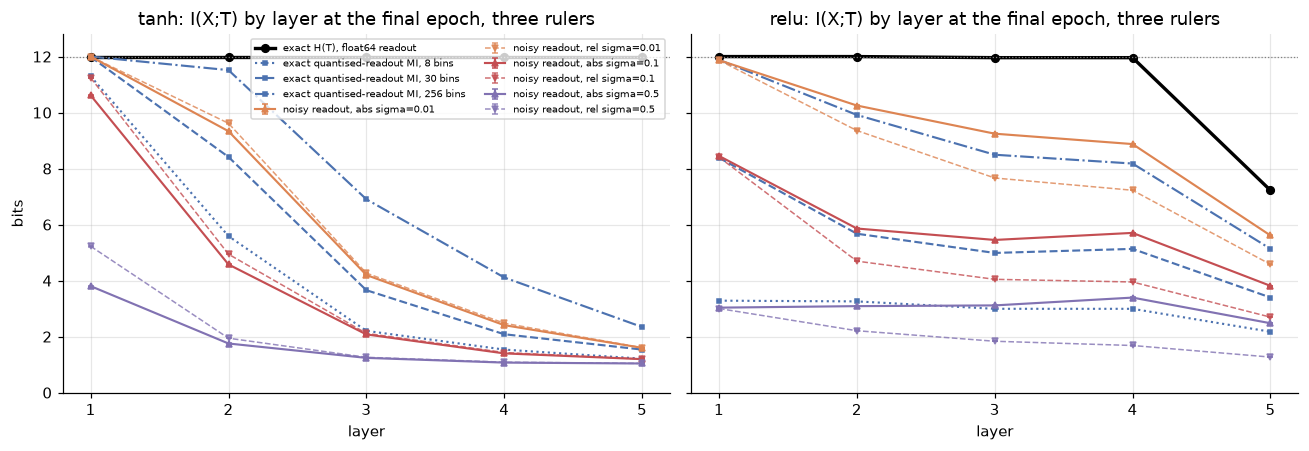

One picture, three rulers. The black curve is the exact H(T) of the float64 readout and the ceiling. The blue
curves are exact too: I(X;Q(T)) for their own quantiser, computed on the enumerated input set — not estimates of
the black curve, and not estimates at all. Only the noisy-readout curves are Monte Carlo expectations, which is
why only they carry error bars. Every coloured curve is a property of the readout as much as of the layer. The
vertical gap between a solid and its dashed twin is activation scale alone.


In [23]:
# The information plane of this experiment, three rulers at once: the exact H(T) of the float64 readout, the
# exact I(X;Q(T)) of a quantised readout at three bin counts (exact for its quantiser on the enumerated input
# set — not an estimate of the black curve), and the noisy readout at three absolute and three relative noise
# levels (Monte Carlo expectations, hence the error bars).
bin_counts = (8, 30, 256)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, act in zip(axes, ("tanh", "relu")):
    hs, _ = forward(res[act][0], X, act)
    L = np.arange(1, len(hs) + 1)
    ax.plot(L, [exact[(act, li)][1] for li in range(len(hs))], "k-o", lw=2.2, ms=5, label="exact H(T), float64 readout")
    for nb_, ls in zip(bin_counts, (":", "--", "-.")):
        ax.plot(L, [layer_information(h, Y, nb_, act)[0] for h in hs], color="#4C72B0", ls=ls, lw=1.4,
                marker="s", ms=3, label=f"exact quantised-readout MI, {nb_} bins")
    for s, c in zip(sigmas, ("#DD8452", "#C44E52", "#8172B2")):
        ax.errorbar(L, [noisy[(act, li, s)][0] for li in range(len(hs))],
                    yerr=[noisy[(act, li, s)][1] for li in range(len(hs))],
                    color=c, lw=1.4, marker="^", ms=4, capsize=2, label=f"noisy readout, abs sigma={s}")
        ax.errorbar(L, [noisy_rel[(act, li, s)][0] for li in range(len(hs))],
                    yerr=[noisy_rel[(act, li, s)][1] for li in range(len(hs))],
                    color=c, lw=1.0, ls="--", marker="v", ms=4, capsize=2, alpha=0.8, label=f"noisy readout, rel sigma={s}")
    ax.axhline(NBITS, color="grey", lw=0.8, ls=":")
    ax.set_title(f"{act}: I(X;T) by layer at the final epoch, three rulers"); ax.set_xlabel("layer"); ax.set_xticks(L)
axes[0].set_ylabel("bits"); axes[0].set_ylim(0, 12.8)
axes[0].legend(fontsize=6.5, loc="upper right", ncol=2)
plt.tight_layout(); plt.show()
print("One picture, three rulers. The black curve is the exact H(T) of the float64 readout and the ceiling. The blue")
print("curves are exact too: I(X;Q(T)) for their own quantiser, computed on the enumerated input set — not estimates of")
print("the black curve, and not estimates at all. Only the noisy-readout curves are Monte Carlo expectations, which is")
print("why only they carry error bars. Every coloured curve is a property of the readout as much as of the layer. The")
print("vertical gap between a solid and its dashed twin is activation scale alone.")

---
## 6. Rate–distortion: the floor under every compression scheme

Entropy answers "how many bits to store this *exactly*." Most of the time you do not want exactly —
you want *good enough*. Rate–distortion theory answers the real question:

$$R(D) \;=\; \min_{\,p(\hat{x}\mid x)\;:\;\mathbb{E}[d(x,\hat{x})]\,\le\, D} I(X;\hat{X}).$$

Given a tolerated distortion $D$, the minimum achievable rate is the smallest mutual information
between the source and its reconstruction. No codec, no neural network, no future invention beats
this curve — it is a property of the source and the distortion measure, not of anyone's cleverness.

We compute it with the **Blahut–Arimoto** algorithm (Blahut 1972; Arimoto 1972), an alternating
minimisation that is about fifteen lines, and we check it against the two sources whose answer is
known in closed form.

In [24]:
def blahut_arimoto(px, dist, beta, iters=3000, tol=1e-12):
    """Returns (rate in bits, expected distortion) at inverse temperature beta."""
    n, m = dist.shape
    q = np.full(m, 1.0 / m)
    for _ in range(iters):
        A = q[None, :] * np.exp(-beta * dist)
        A /= A.sum(axis=1, keepdims=True)                 # p(xhat|x)
        q_new = px @ A
        if np.max(np.abs(q_new - q)) < tol:
            q = q_new; break
        q = q_new
    A = q[None, :] * np.exp(-beta * dist)
    A /= A.sum(axis=1, keepdims=True)
    joint = px[:, None] * A
    R = mutual_information(joint)
    D = float(np.sum(joint * dist))
    return R, D

# --- check 1: binary source, Hamming distortion.  Exact: R(D) = H(p) - H(D) for D <= min(p,1-p).
p1 = 0.3
px = np.array([1 - p1, p1])
dist = np.array([[0.0, 1.0], [1.0, 0.0]])
print("Binary source p=0.3, Hamming distortion")
print(f"{'D':>8} {'R measured':>12} {'H(p)-H(D) exact':>18} {'abs err':>10}")
for beta in (0.05, 0.5, 1.0, 2.0, 3.0, 5.0, 8.0, 15.0):
    R, D = blahut_arimoto(px, dist, beta)
    if D < min(p1, 1 - p1) - 1e-4:
        exact = entropy(px) - (-xlogx(D) - xlogx(1 - D))
        print(f"{D:>8.4f} {R:>12.6f} {exact:>18.6f} {abs(R-exact):>10.2e}")

Binary source p=0.3, Hamming distortion
       D   R measured    H(p)-H(D) exact    abs err
  0.2689     0.041349           0.041349   0.00e+00
  0.1192     0.354226           0.354226   2.22e-16
  0.0474     0.605931           0.605931   0.00e+00
  0.0067     0.823324           0.823324   1.11e-16
  0.0003     0.876937           0.876937   0.00e+00
  0.0000     0.881284           0.881284   1.11e-16


Gaussian source sigma=1, squared-error distortion (241-point quantised grid)
       D   R measured   0.5*log2(1/D)      diff
  0.9999      0.00092         0.00006  +0.00086
  0.9559      0.03250         0.03250  -0.00001
  0.4688      0.54650         0.54651  -0.00001
  0.2285      1.06472         1.06473  -0.00001
  0.1114      1.58294         1.58295  -0.00001
  0.0543      2.10116         2.10117  -0.00001
  0.0265      2.61938         2.61939  -0.00001
  0.0129      3.13760         3.13761  -0.00001
  0.0063      3.65582         3.65583  -0.00001

mean |difference| = 0.00007 bits over 25 points
The residual is the grid: a 241-point discretisation of a continuous source cannot
reproduce a continuous R(D) exactly, and the gap grows at low distortion, where the
code needs finer resolution than the grid has.


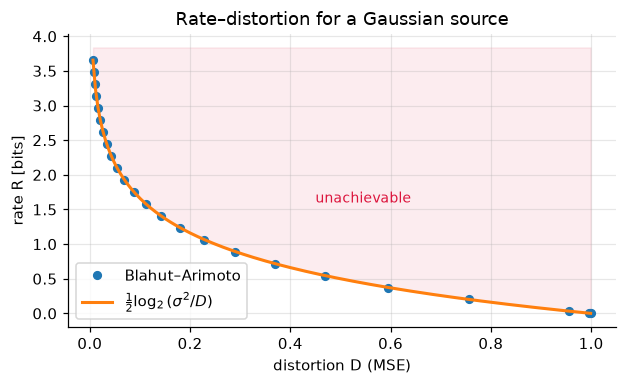

In [25]:
# --- check 2: Gaussian source, squared error.  Exact: R(D) = 0.5 * log2(sigma^2 / D).
sigma = 1.0
grid = np.linspace(-5, 5, 241)
px_g = np.exp(-grid**2 / (2 * sigma**2)); px_g /= px_g.sum()
dist_g = (grid[:, None] - grid[None, :])**2

Rs, Ds, Ex = [], [], []
for beta in np.logspace(-0.7, 1.9, 26):
    R, D = blahut_arimoto(px_g, dist_g, beta, iters=800)
    if 1e-3 < D < sigma**2:
        Rs.append(R); Ds.append(D); Ex.append(0.5 * np.log2(sigma**2 / D))
Rs, Ds, Ex = np.array(Rs), np.array(Ds), np.array(Ex)

print("Gaussian source sigma=1, squared-error distortion (241-point quantised grid)")
print(f"{'D':>8} {'R measured':>12} {'0.5*log2(1/D)':>15} {'diff':>9}")
for i in range(0, len(Ds), 3):
    print(f"{Ds[i]:>8.4f} {Rs[i]:>12.5f} {Ex[i]:>15.5f} {Rs[i]-Ex[i]:>+9.5f}")
print(f"\nmean |difference| = {np.mean(np.abs(Rs - Ex)):.5f} bits over {len(Ds)} points")
print("The residual is the grid: a 241-point discretisation of a continuous source cannot")
print("reproduce a continuous R(D) exactly, and the gap grows at low distortion, where the")
print("code needs finer resolution than the grid has.")

fig, ax = plt.subplots(figsize=(5.8, 3.6))
ax.plot(Ds, Rs, "o", ms=5, label="Blahut–Arimoto")
dd = np.linspace(Ds.min(), min(Ds.max(), 0.999), 200)
ax.plot(dd, 0.5*np.log2(sigma**2/dd), "-", lw=2, label=r"$\frac{1}{2}\log_2(\sigma^2/D)$")
ax.set_xlabel("distortion D (MSE)"); ax.set_ylabel("rate R [bits]")
ax.set_title("Rate–distortion for a Gaussian source"); ax.legend()
ax.fill_between(dd, 0.5*np.log2(sigma**2/dd), ax.get_ylim()[1], alpha=0.08, color="crimson")
ax.text(0.45, 1.6, "unachievable", color="crimson", fontsize=9)
plt.show()

---
## 7. The kernel ↔ Fourier ↔ entropy triangle

[W38](https://artifocial.com/blog/frequency-domain-2026-sep-17) established one edge of a triangle:
**Bochner's theorem**, which says every stationary positive-definite kernel is the Fourier transform
of a non-negative spectral density. This week supplies the second edge.

For a stationary Gaussian process, the differential entropy of $n$ samples is a log-determinant:

$$h(\mathbf{x}) \;=\; \tfrac{1}{2}\log\det\!\left(2\pi e\,K\right),$$

and the **differential entropy rate** — entropy per sample as $n\to\infty$ — is the **log-average** of
the power spectral density (the Kolmogorov–Szegő theorem):

$$\bar{h} \;=\; \frac{1}{2}\cdot\frac{1}{2\pi}\int_{-\pi}^{\pi} \log\!\left(2\pi e\, S(\omega)\right) d\omega
\;=\; \tfrac12\log\!\big(2\pi e\,\sigma_\infty^2\big),\qquad
\sigma_\infty^2 = \exp\!\Big(\tfrac{1}{2\pi}\!\int\log S\Big),$$

where $\sigma_\infty^2$ is the one-step prediction-error variance — the *geometric* mean of the
spectrum. Three objects live near this sentence and only one of them is the entropy rate: the
normalised spectrum $p(\omega) = S/\!\int S$, which is a probability density over frequencies and has
a Shannon entropy $-\!\int p\log p$; the power spectral density $S$ itself; and $\bar h$. The slogan
"the entropy of the spectrum is the entropy rate" equates the first with the third, and it is false —
the cell after the table shows the two functionals coming apart. Differential entropy rate can be
negative, is not a file size, and is invariant under translation only; the OU rows below are negative
in nats and nothing is wrong.

The log-determinant and the log-average are computations in different domains with nothing obviously
in common: one factorises an $n\times n$ matrix, the other integrates a scalar function of frequency.
They give the same number.

The reason is clean enough to verify in one cell. On a periodic grid a stationary kernel matrix is
**circulant**, and the eigenvalues of a circulant matrix are exactly the DFT of its first row — which
*is* the discrete spectral density. So $\log\det K = \sum_k \log \lambda_k$ is a Riemann sum for the
integral. Kernel → spectrum → entropy, with an equals sign at each arrow.

In [26]:
def circulant_kernel_row(n, kind, ell, wraps=4):
    """
    First row of a stationary kernel on a periodic grid of n points, circumference 1.

    'rbf_naive'   : exp(-d^2/2ell^2) of the WRAPPED distance. Intuitive, and not a valid
                    kernel on the circle once ell is comparable to the circumference —
                    see Section 7.1.
    'rbf_wrapped' : the same Gaussian summed over all periodic images. Positive definite
                    by construction: its Fourier coefficients are exp(-2 pi^2 ell^2 k^2) >= 0,
                    which is Bochner's theorem doing the guaranteeing.
    'ou'          : Ornstein-Uhlenbeck / Matern-1/2, exp(-|d|/ell).
    """
    u = np.arange(n) / n                                   # position on the circle in [0,1)
    d = np.minimum(u, 1.0 - u)                             # wrapped distance
    if kind == "rbf_naive":
        return np.exp(-0.5 * (d / ell)**2)
    if kind == "rbf_wrapped":
        m = np.arange(-wraps, wraps + 1)[:, None]
        return np.exp(-0.5 * ((u[None, :] + m) / ell)**2).sum(axis=0)
    if kind == "ou":
        return np.exp(-np.abs(d) / ell)
    raise ValueError(kind)

print("Gaussian-process entropy computed two ways on a periodic grid")
print("(jitter is added to the DIAGONAL, which adds exactly the same constant to every")
print(" circulant eigenvalue — so both sides describe the identical matrix.)")
print()
print(f"{'kernel':>12} {'ell':>6} {'n':>6} {'(1/n)*0.5*logdet(2*pi*e*K)':>27} {'0.5*mean log(2*pi*e*S)':>24} {'|diff|':>10}")
JITTER = 1e-8
diffs = []
for kind in ("rbf_wrapped", "ou"):
    for ell in (0.02, 0.05, 0.15):
        n = 2048
        row = circulant_kernel_row(n, kind, ell).copy()
        row[0] += JITTER                       # ridge on the diagonal of the circulant
        # space domain: full log-determinant of the n x n kernel matrix
        idx = (np.arange(n)[:, None] - np.arange(n)[None, :]) % n
        Kmat = row[idx]
        sign, logdet = np.linalg.slogdet(2 * np.pi * np.e * Kmat)
        left = 0.5 * logdet / n
        # frequency domain: eigenvalues of a circulant are the DFT of its first row
        S = np.real(np.fft.fft(row))
        right = 0.5 * np.mean(np.log(2 * np.pi * np.e * S))
        diffs.append(abs(left - right))
        print(f"{kind:>12} {ell:>6.2f} {n:>6} {left:>27.9f} {right:>24.9f} {abs(left-right):>10.2e}")
print()
print(f"Largest disagreement across all six cases: {max(diffs):.2e}")
print("The two sides are not approximations of each other — they are the same sum, grouped")
print("differently. One factorises a 2048x2048 matrix; the other averages a log over frequency.")

Gaussian-process entropy computed two ways on a periodic grid
(jitter is added to the DIAGONAL, which adds exactly the same constant to every
 circulant eigenvalue — so both sides describe the identical matrix.)

      kernel    ell      n  (1/n)*0.5*logdet(2*pi*e*K)   0.5*mean log(2*pi*e*S)     |diff|


 rbf_wrapped   0.02   2048                -7.384994381             -7.384994383   2.07e-09


 rbf_wrapped   0.05   2048                -7.619080851             -7.619080858   6.44e-09


 rbf_wrapped   0.15   2048                -7.729929533             -7.729929528   4.52e-09


          ou   0.02   2048                -0.102943024             -0.102943024   1.85e-15


          ou   0.05   2048                -0.553805587             -0.553805587   5.77e-15


          ou   0.15   2048                -1.100180300             -1.100180300   2.13e-14

Largest disagreement across all six cases: 6.44e-09
The two sides are not approximations of each other — they are the same sum, grouped
differently. One factorises a 2048x2048 matrix; the other averages a log over frequency.


In [27]:
# What the identity check above does and does not establish. On a circulant matrix, log det K = sum_k log lambda_k
# with lambda_k the DFT of the first row, so the two columns are the same sum grouped differently: the check
# validates the circulant diagonalisation, not the asymptotic Toeplitz statement of Kolmogorov-Szego (that is
# the next cell). And the wrapped-RBF VALUES are properties of the jittered matrix: a squared-exponential kernel
# has a Gaussian spectrum, exp(-2 pi^2 ell^2 k^2), so all but a few dozen of its 2,048 eigenvalues sit below the
# 1e-8 ridge, and the printed "entropy rate" is mostly (2048 - a few)/2048 of 0.5*log(2 pi e * 1e-8).
print("Jitter sensitivity of the circulant entropy-rate expression, n = 2048 (same kernels as the table above)")
print(f"{'kernel':>12} {'ell':>6} {'eig > 1e-8':>11} {'min eig, no jitter':>19} | " + " | ".join(f"{'jitter=' + j:>12}" for j in ("1e-6", "1e-8", "1e-10")) + f" | {'no jitter':>24}")
for kind in ("rbf_wrapped", "ou"):
    for ell in (0.02, 0.05, 0.15):
        S0 = np.real(np.fft.fft(circulant_kernel_row(2048, kind, ell)))
        above = int((S0 > 1e-8).sum())
        vals = [0.5 * np.mean(np.log(2 * np.pi * np.e * (S0 + jit))) for jit in (1e-6, 1e-8, 1e-10)]
        nonpos = int((S0 <= 0).sum())      # computed eigenvalues that are zero or NEGATIVE: FFT roundoff, not the spectrum
        noj = f"{0.5 * np.mean(np.log(2 * np.pi * np.e * S0)):.4f}" if nonpos == 0 else f"unresolved ({nonpos} eig <= 0)"
        print(f"{kind:>12} {ell:>6.2f} {above:>11} {S0.min():>19.3e} | " + " | ".join(f"{v:>12.4f}" for v in vals) + f" | {noj:>24}")
print()
print("Reading: the OU rows (spectrum ~ 1/omega^2, every eigenvalue far above the ridge) do not move with the jitter.")
print("The wrapped-RBF rows move by nats per decade of jitter, because for most of their eigenvalues the ridge IS the")
print("value. Without the ridge the finite circulant spectrum is too ill-conditioned to evaluate in float64: the FFT of")
print("the kernel row returns hundreds of small NEGATIVE and zero eigenvalues (the 'min eig' column, ~ -1e-14; the count")
print("in the last column) where the mathematical wrapped-Gaussian spectrum is strictly positive, so the unregularised")
print("log-determinant is numerically UNRESOLVED — not -inf, and not a failure of Szego's hypothesis int log S > -inf,")
print("which this kernel satisfies. The jittered values describe a different covariance model, K + eps*I: the wrapped-RBF")
print("'entropy rate' printed above is a statement about K + 1e-8 I, not a measurement of the RBF process's entropy rate.")

Jitter sensitivity of the circulant entropy-rate expression, n = 2048 (same kernels as the table above)
      kernel    ell  eig > 1e-8  min eig, no jitter |  jitter=1e-6 |  jitter=1e-8 | jitter=1e-10 |                no jitter
 rbf_wrapped   0.02         109          -1.421e-14 |      -5.1975 |      -7.3850 |      -9.5603 | unresolved (1010 eig <= 0)
 rbf_wrapped   0.05          45          -1.621e-14 |      -5.3635 |      -7.6191 |      -9.8698 | unresolved (1010 eig <= 0)
 rbf_wrapped   0.15          15          -2.620e-14 |      -5.4435 |      -7.7299 |     -10.0150 | unresolved (1039 eig <= 0)
          ou   0.02        2048           1.221e-02 |      -0.1029 |      -0.1029 |      -0.1029 |                  -0.1029
          ou   0.05        2048           4.883e-03 |      -0.5538 |      -0.5538 |      -0.5538 |                  -0.5538
          ou   0.15        2048           1.570e-03 |      -1.1000 |      -1.1002 |      -1.1002 |                  -1.1002

Reading: the OU rows 

In [28]:
# The Toeplitz statement, tested as a limit. For an AR(1) process with unit innovation the n-sample covariance is
# Toeplitz, NOT circulant: K_n[i,j] = phi^|i-j| / (1 - phi^2). Its per-sample entropy has an exact finite-n form,
#   (1/n) h(x_1..x_n) = 0.5 log(2 pi e) + (1/(2n)) log(1/(1 - phi^2)),
# because h(x_1..x_n) = h(x_1) + (n-1) h(innovation). Kolmogorov-Szego says the limit is 0.5 log(2 pi e) = 1.4189
# nats; the gap closes like 1/n, and a log-determinant of the actual Toeplitz matrix has to reproduce that.
phi_t = 0.9
limit = 0.5 * np.log(2 * np.pi * np.e)
print(f"Toeplitz AR(1), phi = {phi_t}, unit innovation: (1/n)*0.5*logdet(2 pi e K_n) against the Szego limit {limit:.6f} nats, no jitter")
print(f"{'n':>6} {'logdet form':>13} {'exact finite-n':>15} {'gap to limit':>13} {'n * gap':>9}")
for n_t in (16, 64, 256, 1024, 4096):
    i_t = np.arange(n_t)
    Kn = phi_t ** np.abs(i_t[:, None] - i_t[None, :]) / (1 - phi_t ** 2)
    sign_t, logdet_t = np.linalg.slogdet(2 * np.pi * np.e * Kn)
    left_t = 0.5 * logdet_t / n_t
    exact_t = limit + np.log(1 / (1 - phi_t ** 2)) / (2 * n_t)
    print(f"{n_t:>6} {left_t:>13.6f} {exact_t:>15.6f} {left_t - limit:>13.6f} {n_t * (left_t - limit):>9.4f}")
print()
print(f"n * gap stays at 0.5*log(1/(1-phi^2)) = {0.5 * np.log(1 / (1 - phi_t ** 2)):.4f}: the Toeplitz log-determinant converges to the")
print("asymptotic entropy rate at rate 1/n, with no jitter and no circulant shortcut. That is the theorem's content;")
print("the circulant table above is the finite-n identity it reduces to on a periodic grid.")

Toeplitz AR(1), phi = 0.9, unit innovation: (1/n)*0.5*logdet(2 pi e K_n) against the Szego limit 1.418939 nats, no jitter
     n   logdet form  exact finite-n  gap to limit   n * gap
    16      1.470836        1.470836      0.051898    0.8304
    64      1.431913        1.431913      0.012974    0.8304
   256      1.422182        1.422182      0.003244    0.8304
  1024      1.419749        1.419749      0.000811    0.8304


  4096      1.419141        1.419141      0.000203    0.8304

n * gap stays at 0.5*log(1/(1-phi^2)) = 0.8304: the Toeplitz log-determinant converges to the
asymptotic entropy rate at rate 1/n, with no jitter and no circulant shortcut. That is the theorem's content;
the circulant table above is the finite-n identity it reduces to on a periodic grid.


In [29]:
# What that identity is NOT: the Shannon entropy of the normalised spectrum. Two functionals of the
# same S(omega), side by side, plus the one-line counter-example — multiply the kernel by 4.
def entropy_rate_nats(S):
    return 0.5 * np.log(2 * np.pi * np.e) + 0.5 * np.mean(np.log(S))

def normalised_spectrum_entropy_nats(S):
    """Shannon entropy of p(omega) = S / integral S on [-pi, pi), Riemann sum, in nats."""
    dw = 2 * np.pi / len(S)
    p = S / (S.sum() * dw)
    return float(-np.sum(p * np.log(p)) * dw)

n = 2048
print(f"{'kernel':>14} {'entropy rate h [nats]':>22} {'-int p log p [nats]':>21}")
rows_ = []
for kind, ell in (("ou", 0.02), ("ou", 0.05), ("ou", 0.15)):
    S = np.real(np.fft.fft(circulant_kernel_row(n, kind, ell)))
    rows_.append((kind, ell, entropy_rate_nats(S), normalised_spectrum_entropy_nats(S)))
    print(f"{kind+' ell='+str(ell):>14} {rows_[-1][2]:>22.6f} {rows_[-1][3]:>21.6f}")
print()
S = np.real(np.fft.fft(circulant_kernel_row(n, "ou", 0.05)))
h1, e1 = entropy_rate_nats(S), normalised_spectrum_entropy_nats(S)
h4, e4 = entropy_rate_nats(4 * S), normalised_spectrum_entropy_nats(4 * S)
print("Multiply the kernel (hence S) by 4:")
print(f"  entropy rate      : {h1:.6f} -> {h4:.6f} nats   (change {h4-h1:+.6f} = 0.5*ln 4 = {0.5*np.log(4):.6f} = exactly 1 bit)")
print(f"  -int p log p      : {e1:.6f} -> {e4:.6f} nats   (change {e4-e1:+.1e})")
if abs((h4 - h1) - 0.5*np.log(4)) < 1e-9 and abs(e4 - e1) < 1e-9:
    print("One functional moved by exactly one bit per sample, the other did not move at all.")
    print("They cannot be the same quantity. The entropy rate is the log-AVERAGE of S, not its Shannon entropy.")
else:
    print("Unexpected: check the normalisation before quoting.")

        kernel  entropy rate h [nats]   -int p log p [nats]
   ou ell=0.02              -0.102943             -1.205886
   ou ell=0.05              -0.553806             -2.107612
   ou ell=0.15              -1.100182             -3.199425

Multiply the kernel (hence S) by 4:
  entropy rate      : -0.553806 -> 0.139341 nats   (change +0.693147 = 0.5*ln 4 = 0.693147 = exactly 1 bit)
  -int p log p      : -2.107612 -> -2.107612 nats   (change +0.0e+00)
One functional moved by exactly one bit per sample, the other did not move at all.
They cannot be the same quantity. The entropy rate is the log-AVERAGE of S, not its Shannon entropy.


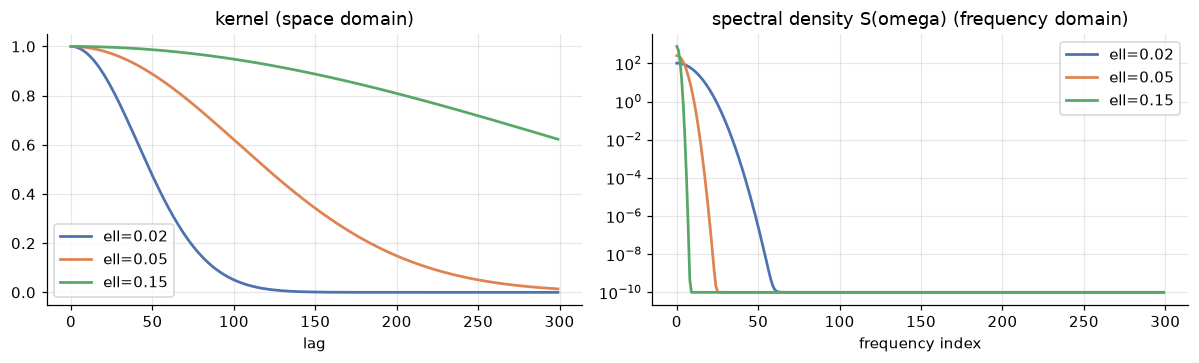

Spectral flatness = geometric mean of S / arithmetic mean of S.
With the theorem stated correctly it is exp[2*(h - h_white)], natural logs, where h_white is the
entropy rate of white noise at the same power — a normalised entropy RATE (the factor 2 undoes
the 1/2 in front of the log). 1 means white (maximum rate for that power), small means structured.

               process    flatness                    reading
           white noise  1.0000e+00        white / max entropy
OU (Matern-1/2) ell=0.02  4.7655e-02   structured, compressible
OU (Matern-1/2) ell=0.05  1.9342e-02   structured, compressible
OU (Matern-1/2) ell=0.15  6.4851e-03   structured, compressible

flatness vs exp[2(h - h_white)]: largest disagreement over the OU cases = 3.47e-18

Longer correlation length -> more peaked spectrum -> lower flatness -> lower entropy rate.
That chain is why compression works at all, FOR A GAUSSIAN PROCESS: structure in space is
concentration in frequency is a low entropy rate. Two processe

In [30]:
# What the identity buys you: entropy becomes readable off the spectrum.
n = 2048
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
for ell, c in zip((0.02, 0.05, 0.15), ("#4C72B0", "#DD8452", "#55A868")):
    row = circulant_kernel_row(n, "rbf_wrapped", ell)
    S = np.real(np.fft.fft(row)) + 1e-10
    half = n // 2
    ax[0].plot(row[:half][:300], c=c, lw=1.8, label=f"ell={ell}")
    ax[1].semilogy(np.maximum(S[:half][:300], 1e-12), c=c, lw=1.8, label=f"ell={ell}")
ax[0].set_title("kernel (space domain)"); ax[0].set_xlabel("lag")
ax[1].set_title("spectral density S(omega) (frequency domain)"); ax[1].set_xlabel("frequency index")
ax[0].legend(); ax[1].legend()
plt.show()

print("Spectral flatness = geometric mean of S / arithmetic mean of S.")
print("With the theorem stated correctly it is exp[2*(h - h_white)], natural logs, where h_white is the")
print("entropy rate of white noise at the same power — a normalised entropy RATE (the factor 2 undoes")
print("the 1/2 in front of the log). 1 means white (maximum rate for that power), small means structured.")
print()
print(f"{'process':>22} {'flatness':>11} {'reading':>26}")
n = 2048
white = np.zeros(n); white[0] = 1.0
cases = [("white noise", white)]
for ell in (0.02, 0.05, 0.15):
    cases.append((f"OU (Matern-1/2) ell={ell}", circulant_kernel_row(n, "ou", ell)))
for (name, row) in cases:
    S = np.real(np.fft.fft(row))
    flat = np.exp(np.mean(np.log(S))) / np.mean(S)
    tag = "white / max entropy" if flat > 0.9 else ("broadband" if flat > 0.1 else "structured, compressible")
    print(f"{name:>22} {flat:>11.4e} {tag:>26}")
print()
# Verify the flatness identity numerically rather than asserting it.
worst_flat = 0.0
for (name, row) in cases[1:]:
    S = np.real(np.fft.fft(row))
    geo_over_arith = np.exp(np.mean(np.log(S))) / np.mean(S)
    h = 0.5 * np.log(2 * np.pi * np.e) + 0.5 * np.mean(np.log(S))
    h_white = 0.5 * np.log(2 * np.pi * np.e * np.mean(S))      # white noise, same variance
    worst_flat = max(worst_flat, abs(geo_over_arith - np.exp(2 * (h - h_white))))
print(f"flatness vs exp[2(h - h_white)]: largest disagreement over the OU cases = {worst_flat:.2e}")
print()
print("Longer correlation length -> more peaked spectrum -> lower flatness -> lower entropy rate.")
print("That chain is why compression works at all, FOR A GAUSSIAN PROCESS: structure in space is")
print("concentration in frequency is a low entropy rate. Two processes with the same covariance and")
print("different non-Gaussian laws have different entropy rates; the Gaussian one is the largest.")

### 7.1 Two different things that both look like "negative eigenvalues"

The table above uses `rbf_wrapped` rather than the obvious Gaussian-of-wrapped-distance, and the
reason is the most instructive accident in this notebook.

The first version computed the RBF row as $\exp(-d^2/2\ell^2)$ where $d$ is the wrapped distance
around the circle — the intuitive thing, and what most people would write. It produced a `nan` in the
entropy-rate column at $\ell=0.15$. The natural diagnosis is underflow: the squared-exponential
kernel has a **Gaussian** spectral density decaying like $e^{-\omega^2}$, so its small eigenvalues
fall below double precision, the FFT returns rounding noise that is as often negative as positive,
and $\log$ of a negative number is `nan`. That diagnosis is right for $\ell=0.02$ and $\ell=0.05$.

**It is wrong for $\ell=0.15$, and the measurement says so.** The most negative eigenvalue there is
about $-1.9\times10^{-1}$ — not $10^{-14}$. That is not rounding. A Gaussian evaluated at wrapped
distance is simply **not a positive-definite kernel on the circle** once the lengthscale is
comparable to the circumference: it is a perfectly sensible-looking similarity function that no
Gaussian process has. This is precisely the failure
[W38's Bochner section](https://artifocial.com/blog/bochner-theorem-kernel-fourier-bridge-2026-sep-27)
found for the box similarity, arriving here in a friendlier disguise.

The fix is the one Bochner's theorem hands you: build the kernel so its spectrum **cannot** be
negative. The *wrapped* Gaussian — the same bump summed over all its periodic images — has Fourier
coefficients $e^{-2\pi^2\ell^2k^2}$, non-negative by construction and therefore a valid kernel at
every lengthscale.

So the two failure modes need different repairs, and telling them apart requires looking at the
magnitude rather than the sign:

| symptom | cause | repair |
|---|---|---|
| eigenvalues at $\sim -10^{-14}$ | FFT roundoff on an underflowing spectrum — **numerical**, the log-determinant is unresolved, not $-\infty$ | jitter on the diagonal (and say the result describes $K+\varepsilon I$) |
| eigenvalues at $\sim -10^{-1}$ | not a kernel on this domain — **modelling** | choose a kernel with a non-negative spectrum |

Jitter "fixes" the second one too, in the sense that it stops the crash. It does so by quietly
replacing your model with a different one.

Note also that the jitter above is added to the **diagonal**, which adds the identical constant to
every circulant eigenvalue, so both sides of the identity still describe the same matrix. Adding it
to the spectrum alone — the tempting one-character version — would have made the two sides disagree
while both continued to print plausible numbers.

In [31]:
n = 2048
print(f"{'kernel':>18} {'min eigenvalue':>17} {'max eigenvalue':>15} {'condition number':>18} {'# eigenvalues < 0':>18}")
for kind, ell in (("rbf_naive", 0.02), ("rbf_naive", 0.05), ("rbf_naive", 0.15),
                  ("rbf_wrapped", 0.02), ("rbf_wrapped", 0.05), ("rbf_wrapped", 0.15),
                  ("ou", 0.02), ("ou", 0.15)):
    row = circulant_kernel_row(n, kind, ell)
    S = np.real(np.fft.fft(row))                    # exact eigenvalues of the circulant
    neg = int((S < 0).sum())
    cond = S.max() / S.min() if S.min() > 0 else np.inf
    print(f"{kind+' ell='+str(ell):>18} {S.min():>17.3e} {S.max():>15.3e} {cond:>18.3e} {neg:>18}")
print()
print(f"float64 resolves about {np.finfo(float).eps:.2e} relative to the largest value.")
print()
print("Read the MAGNITUDE of the negative eigenvalues, not merely the sign:")
for kind, ell in (("rbf_naive", 0.05), ("rbf_naive", 0.15), ("rbf_wrapped", 0.15)):
    S = np.real(np.fft.fft(circulant_kernel_row(n, kind, ell)))
    rel = S.min() / S.max()
    verdict = ("positive definite" if S.min() >= 0 else
               ("NUMERICAL: rounded through zero" if abs(rel) < 1e-10 else
                "MODELLING: genuinely not a kernel here"))
    print(f"  {kind+' ell='+str(ell):>20}  min/max = {rel:>+11.3e}   {verdict}")
print()
print("Jitter repairs the first. It only conceals the second — it stops the crash by")
print("replacing your model with a slightly different one that happens to be valid.")

            kernel    min eigenvalue  max eigenvalue   condition number  # eigenvalues < 0
rbf_naive ell=0.02        -1.421e-14       1.027e+02                inf                981
rbf_naive ell=0.05        -1.621e-14       2.567e+02                inf                986
rbf_naive ell=0.15        -1.923e-01       7.694e+02                inf               1019
rbf_wrapped ell=0.02        -1.421e-14       1.027e+02                inf                981
rbf_wrapped ell=0.05        -1.621e-14       2.567e+02                inf                986
rbf_wrapped ell=0.15        -2.620e-14       7.700e+02                inf               1003
       ou ell=0.02         1.221e-02       8.192e+01          6.712e+03                  0
       ou ell=0.15         1.570e-03       5.925e+02          3.775e+05                  0

float64 resolves about 2.22e-16 relative to the largest value.

Read the MAGNITUDE of the negative eigenvalues, not merely the sign:
    rbf_naive ell=0.05  min/max =  -6.316

---
## 8. Engineering callout: the two numerical traps

Information-theoretic code fails in two characteristic ways, and both are silent.

**1. `log(0)`.** Handled in Section 1 by masking. The common alternative — clipping probabilities to
$\varepsilon$ — does not error, does not warn, and *changes the answer* by an amount that depends on
$\varepsilon$ and on how many zeros the distribution has.

**2. `exp` overflow in softmax and log-sum-exp.** The naive implementation overflows at logits around
710 in float64 and around 88 in float32 — and float32 is what your model is actually using. The fix
is to subtract the maximum before exponentiating, which is exact rather than approximate.

In [32]:
# Trap 1: clipping vs masking.
p = np.array([0.7, 0.3, 0.0, 0.0, 0.0])
print(f"masked  H(p) = {entropy(p):.10f} bits   (correct)")
for eps in (1e-3, 1e-6, 1e-10):
    q = np.clip(p, eps, None); q = q / q.sum()
    print(f"clipped H(p) at eps={eps:<6g} = {entropy(q):.10f} bits   error {entropy(q)-entropy(p):+.2e}")

# Trap 2: overflow.
print("\nnaive softmax vs shifted softmax")
for scale, dt in ((100.0, np.float64), (800.0, np.float64), (100.0, np.float32)):
    z = np.array([scale, scale - 1.0, scale - 2.0], dtype=dt)
    with np.errstate(over="ignore", invalid="ignore"):
        e = np.exp(z); naive = e / e.sum()
    shifted = softmax(z.astype(np.float64))
    ok = np.all(np.isfinite(naive))
    print(f"  dtype={np.dtype(dt).name:<8} max logit {scale:6.0f}: naive finite? {str(ok):>5}   "
          f"naive[0]={naive[0]!s:<10.10}  shifted[0]={shifted[0]:.6f}")
print("\nfloat32 overflows at exp(~88). Models train in float32 or bfloat16. Shift, always.")

masked  H(p) = 0.8812908992 bits   (correct)
clipped H(p) at eps=0.001  = 0.9127844694 bits   error +3.15e-02
clipped H(p) at eps=1e-06  = 0.8813523780 bits   error +6.15e-05
clipped H(p) at eps=1e-10  = 0.8812909094 bits   error +1.01e-08

naive softmax vs shifted softmax
  dtype=float64  max logit    100: naive finite?  True   naive[0]=0.66524095  shifted[0]=0.665241
  dtype=float64  max logit    800: naive finite? False   naive[0]=nan         shifted[0]=0.665241
  dtype=float32  max logit    100: naive finite? False   naive[0]=nan         shifted[0]=0.665241

float32 overflows at exp(~88). Models train in float32 or bfloat16. Shift, always.


---
## Summary of what was measured

| # | Claim | Number produced here |
|---|---|---|
| 1 | Cross-entropy = entropy + KL | max deviation $\sim10^{-15}$ over 20,000 random pairs |
| 2 | KL ≥ 0, with no exceptions | 0 negatives in 100,000 random pairs |
| 3 | Label smoothing installs an irreducible loss floor | computed per $(K,\varepsilon)$ in §2.1 |
| 4 | Post-processing cannot create information | 0 violations in 5,000 random Markov chains |
| 5 | The plug-in MI estimator is biased, with a regime-dependent sign | reads high under independence, matching $(K{-}1)(L{-}1)/(2N\ln 2)$ across four decades of $N$; reads a full bit low for $X=Y$ at $N=1$; permutation null at $N=200$ |
| 6 | The binned "compression" depends on the nonlinearity *and* on the bin count; the exact $I(X;T)=H(T)$ needs no bins | §5, three tables |
| 7 | Blahut–Arimoto recovers the closed-form $R(D)$ | binary and Gaussian sources, §6 |
| 8 | Entropy rate = log-determinant = log-average of the spectral density (Kolmogorov–Szegő), and ≠ the Shannon entropy of the normalised spectrum | circulant identity to $6.4\times10^{-9}$; Toeplitz AR(1) converges to the limit at rate $1/n$; the wrapped-RBF values are jitter-dominated and say so; ×4 kernel moves one functional by exactly 1 bit and the other by 0, §7 |

The thread running through all eight: information theory gives you quantities that are *exactly*
defined and *approximately* measurable, and the gap between those two facts is where practitioners
get hurt. Sections 4 and 5 are that gap.

**Next:** [`01_entropy_across_the_series.ipynb`](./01_entropy_across_the_series.ipynb) applies these
tools to the systems we built in earlier weeks — diffusion schedules, the rate–distortion view of the
ELBO, self-play stability, and model collapse under recursive training.